# Visit with Us — Wellness Tourism Package Purchase Prediction
### End-to-end MLOps project: data registration → preparation → tracked model training → Docker/Streamlit deployment → GitHub Actions CI/CD

> **How to run:** start Jupyter from the project root (the folder that contains `tourism_project/`), select the kernel of your virtual environment, then **Kernel → Restart & Run All**. Edit only the *Configuration* cell.

# Problem Statement
## Business Context
"Visit with Us," a leading travel company, is revolutionizing the tourism industry by leveraging data-driven strategies to optimize operations and customer engagement. While introducing a new package offering, such as the Wellness Tourism Package, the company faces challenges in targeting the right customers efficiently. The manual approach to identifying potential customers is inconsistent, time-consuming, and prone to errors, leading to missed opportunities and suboptimal campaign performance.

To address these issues, the company aims to implement a scalable and automated system that integrates customer data, predicts potential buyers, and enhances decision-making for marketing strategies. By utilizing an MLOps pipeline, the company seeks to achieve seamless integration of data preprocessing, model development, deployment, and CI/CD practices for continuous improvement.

## Objective
As an MLOps Engineer at "Visit with Us", design and deploy an MLOps pipeline on GitHub that automates the end-to-end workflow for predicting whether a customer will purchase the newly introduced **Wellness Tourism Package _before contacting them_**: data cleaning, preprocessing, transformation, model building, training, evaluation and deployment, with GitHub Actions providing CI/CD.

## Data Description
| Group | Column | Meaning |
|---|---|---|
| Customer | CustomerID | Unique identifier |
| Customer | **ProdTaken** | **Target** – purchased a package (0 = No, 1 = Yes) |
| Customer | Age, Gender, MaritalStatus, Occupation, Designation, MonthlyIncome | Demographics / work |
| Customer | TypeofContact | Company Invited or Self Enquiry |
| Customer | CityTier | City development tier (1 > 2 > 3) |
| Customer | NumberOfPersonVisiting, NumberOfChildrenVisiting (<5 yrs) | Travel party |
| Customer | PreferredPropertyStar, NumberOfTrips (per year), Passport, OwnCar | Travel profile |
| Interaction | PitchSatisfactionScore, ProductPitched, NumberOfFollowups, DurationOfPitch | Sales interaction (**only exists after contact**) |

## Key design decision: score customers *before* contact
The goal is to decide **whom to contact**, so the model may only use information that exists *before* the first sales call. The four interaction columns (`DurationOfPitch`, `NumberOfFollowups`, `PitchSatisfactionScore`, `ProductPitched`) are produced by the sales process itself, so using them would leak information that is unavailable at decision time. They are excluded from the model (the EDA below shows they carry little signal anyway, and that `ProductPitched` is just a relabelling of `Designation`).

## Architecture
```
tourism.csv ──► [preflight: token · config · tests] ──► [register-dataset] ──► HF Dataset repo
                      │
                [data-prep]  clean · de-duplicate · split ──► HF Dataset repo (train/test)
                      │
              [model-training]  GridSearchCV · MLflow tracking · threshold tuning ──► HF Model repo
                      │
              [deploy-hosting]  Dockerfile + Streamlit app ──► HF Space (public frontend)
        (all jobs run automatically in GitHub Actions on every push to main, after a preflight check)
```

# 0. Setup & Configuration
Fill in the four values below. The Hugging Face token is requested securely (hidden input) and is **never written to a file or committed**.

In [1]:
# ======================  EDIT ONLY THIS CELL  ======================
HF_USERNAME     = "CasioThief"      # Hugging Face username (Spaces must be public)
GITHUB_USERNAME = "samkenzo"  # GitHub username
GITHUB_REPO     = "visit-with-us-mlops"      # GitHub repository name (public), e.g. "visit-with-us-mlops"
# ===================================================================

import os, sys, getpass, platform
from pathlib import Path

assert not HF_USERNAME.startswith("YOUR_") and not GITHUB_USERNAME.startswith("YOUR_") and not GITHUB_REPO.startswith("YOUR_"), \
    "Please fill in HF_USERNAME, GITHUB_USERNAME and GITHUB_REPO above."

PY = sys.executable            # always use the Python of THIS kernel when running the pipeline scripts
print("Python executable :", PY)
print("Python version    :", platform.python_version())
print("Working directory :", Path.cwd())

import sklearn, pandas, numpy
print(f"scikit-learn {sklearn.__version__} | pandas {pandas.__version__} | numpy {numpy.__version__}")
if sklearn.__version__ != "1.5.2":
    print("WARNING: requirements.txt pins scikit-learn==1.5.2. The model trained here is deployed to a container "
          "using that exact version, so install the pinned requirements before training.")

# Hugging Face WRITE token (hidden prompt; press Enter to skip -> HF steps are skipped and everything runs locally)
if not os.getenv("HF_TOKEN"):
    try:
        token = getpass.getpass("Paste your Hugging Face WRITE token (input hidden, Enter to skip): ").strip()
    except Exception:          # non-interactive run (no input available) -> behave as "skipped"
        token = ""
    if token:
        os.environ["HF_TOKEN"] = token
if os.getenv("HF_TOKEN"):
    os.environ["HF_TOKEN"] = os.environ["HF_TOKEN"].strip()   # a pasted newline/space is the #1 cause of 401 errors
print("HF_TOKEN available:", bool(os.getenv("HF_TOKEN")))

# project folders required by the rubric
for folder in ["tourism_project/data", "tourism_project/model_building", "tourism_project/deployment",
               "tourism_project/hosting", ".github/workflows", "screenshots", "tests"]:
    os.makedirs(folder, exist_ok=True)
assert Path("tourism_project/data/tourism.csv").exists(), \
    "Copy tourism.csv into tourism_project/data/ and make sure Jupyter was started from the project root."
print("Dataset found: tourism_project/data/tourism.csv")

Python executable : /Users/swarajkhair/Desktop/exl/project/.venv/bin/python
Python version    : 3.11.17
Working directory : /Users/swarajkhair/Desktop/exl/project
scikit-learn 1.5.2 | pandas 2.2.3 | numpy 1.26.4


Paste your Hugging Face WRITE token (input hidden, Enter to skip):  ········


HF_TOKEN available: True
Dataset found: tourism_project/data/tourism.csv


In [2]:
# Shared configuration module used by every pipeline script (HF repo names come from HF_USERNAME above)
CONFIG_TEMPLATE = '''"""Central configuration shared by every pipeline script (written by the notebook)."""
from pathlib import Path

HF_USERNAME = "YOUR_HF_USERNAME"

PROJECT_DIR = Path(__file__).resolve().parent
REPO_ROOT = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / "data"
ARTIFACT_DIR = PROJECT_DIR / "model_building" / "artifacts"
DEPLOY_DIR = PROJECT_DIR / "deployment"
RAW_DATA_PATH = DATA_DIR / "tourism.csv"

# Hugging Face Hub repositories (created automatically by the pipeline scripts)
DATASET_REPO = f"{HF_USERNAME}/visit-with-us-tourism-data"
MODEL_REPO = f"{HF_USERNAME}/visit-with-us-tourism-model"
SPACE_REPO = f"{HF_USERNAME}/visit-with-us-tourism-app"

MODEL_FILE = "tourism_model_v1.joblib"
TARGET = "ProdTaken"
ID_COLUMNS = ["Unnamed: 0", "CustomerID"]

# Only known AFTER the salesperson contacts the customer -> excluded, because the
# model must score a customer BEFORE any contact is made.
POST_CONTACT_COLUMNS = [
    "DurationOfPitch",
    "NumberOfFollowups",
    "PitchSatisfactionScore",
    "ProductPitched",
]

# Columns the raw file must contain (checked by preflight.py and prep.py)
FEATURE_COLUMNS = [
    "Age", "TypeofContact", "CityTier", "Occupation", "Gender", "NumberOfPersonVisiting",
    "PreferredPropertyStar", "MaritalStatus", "NumberOfTrips", "Passport", "OwnCar",
    "NumberOfChildrenVisiting", "Designation", "MonthlyIncome",
]

TEST_SIZE = 0.2
RANDOM_STATE = 42
CV_FOLDS = 5

EXPERIMENT_NAME = "visit-with-us-wellness-tourism"
MLFLOW_DEFAULT_URI = "sqlite:///" + str(REPO_ROOT / "mlflow.db")
'''
Path("tourism_project/config.py").write_text(CONFIG_TEMPLATE.replace("YOUR_HF_USERNAME", HF_USERNAME))
print(Path("tourism_project/config.py").read_text())

"""Central configuration shared by every pipeline script (written by the notebook)."""
from pathlib import Path

HF_USERNAME = "CasioThief"

PROJECT_DIR = Path(__file__).resolve().parent
REPO_ROOT = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / "data"
ARTIFACT_DIR = PROJECT_DIR / "model_building" / "artifacts"
DEPLOY_DIR = PROJECT_DIR / "deployment"
RAW_DATA_PATH = DATA_DIR / "tourism.csv"

# Hugging Face Hub repositories (created automatically by the pipeline scripts)
DATASET_REPO = f"{HF_USERNAME}/visit-with-us-tourism-data"
MODEL_REPO = f"{HF_USERNAME}/visit-with-us-tourism-model"
SPACE_REPO = f"{HF_USERNAME}/visit-with-us-tourism-app"

MODEL_FILE = "tourism_model_v1.joblib"
TARGET = "ProdTaken"
ID_COLUMNS = ["Unnamed: 0", "CustomerID"]

# Only known AFTER the salesperson contacts the customer -> excluded, because the
# model must score a customer BEFORE any contact is made.
POST_CONTACT_COLUMNS = [
    "DurationOfPitch",
    "NumberOfFollowups",
    "PitchSatisfactionScore",
    "Pro

In [3]:
import importlib
sys.path.insert(0, str(Path("tourism_project").resolve()))
sys.path.insert(0, str(Path("tourism_project/model_building").resolve()))
import config
importlib.reload(config)

SPACE_URL   = f"https://huggingface.co/spaces/{config.SPACE_REPO}"
MODEL_URL   = f"https://huggingface.co/{config.MODEL_REPO}"
DATASET_URL = f"https://huggingface.co/datasets/{config.DATASET_REPO}"
GITHUB_URL  = f"https://github.com/{GITHUB_USERNAME}/{GITHUB_REPO}"

from IPython.display import display, Markdown, Image
display(Markdown(f"""
### Submission links
| Item | Link |
|---|---|
| **GitHub repository** | [{GITHUB_URL}]({GITHUB_URL}) |
| **Hugging Face Space (Streamlit frontend)** | [{SPACE_URL}]({SPACE_URL}) |
| Hugging Face Model repo | [{MODEL_URL}]({MODEL_URL}) |
| Hugging Face Dataset repo | [{DATASET_URL}]({DATASET_URL}) |
"""))


### Submission links
| Item | Link |
|---|---|
| **GitHub repository** | [https://github.com/samkenzo/visit-with-us-mlops](https://github.com/samkenzo/visit-with-us-mlops) |
| **Hugging Face Space (Streamlit frontend)** | [https://huggingface.co/spaces/CasioThief/visit-with-us-tourism-app](https://huggingface.co/spaces/CasioThief/visit-with-us-tourism-app) |
| Hugging Face Model repo | [https://huggingface.co/CasioThief/visit-with-us-tourism-model](https://huggingface.co/CasioThief/visit-with-us-tourism-model) |
| Hugging Face Dataset repo | [https://huggingface.co/datasets/CasioThief/visit-with-us-tourism-data](https://huggingface.co/datasets/CasioThief/visit-with-us-tourism-data) |


## 0.1 Shared helpers, preflight check and data-preparation module
These small modules are written first because the exploratory analysis below imports `prep.py`. `pipeline_utils.py` adds retries around Hugging Face calls; `preflight.py` stops early with a plain-English message if the username, token or data are wrong (the same check runs first in GitHub Actions).

In [4]:
%%writefile tourism_project/pipeline_utils.py
"""Small helpers shared by the pipeline scripts (kept dependency-free on purpose)."""
import time

# HTTP status codes that will not fix themselves, so retrying only wastes time.
_NO_RETRY = (401, 403, 404)


def retry(fn, tries: int = 3, delay: float = 4.0, what: str = "operation"):
    """Call fn(); on a transient failure wait and try again, then re-raise the last error."""
    last = None
    for attempt in range(1, tries + 1):
        try:
            return fn()
        except Exception as exc:  # noqa: BLE001
            last = exc
            status = getattr(getattr(exc, "response", None), "status_code", None)
            if status in _NO_RETRY:
                raise
            print(f"  {what} failed (attempt {attempt}/{tries}): {type(exc).__name__}: {exc}")
            if attempt < tries:
                time.sleep(delay * attempt)
    raise last

Overwriting tourism_project/pipeline_utils.py


In [5]:
%%writefile tourism_project/model_building/preflight.py
"""Step 0 - Preflight: stop early, with a plain-English message, on the usual first-run problems.

    python preflight.py                 # strict: Hugging Face token is required (used by CI)
    python preflight.py --allow-no-token  # notebook/local use: skip the Hub checks if no token is set
"""
import os
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
import config  # noqa: E402

problems, warnings_ = [], []


def check_config_and_data():
    if config.HF_USERNAME.startswith("YOUR_") or not config.HF_USERNAME.strip():
        problems.append(
            "HF_USERNAME in tourism_project/config.py is still the placeholder. Run the notebook's "
            "configuration cell (it writes config.py) or edit the file, then commit and push it."
        )
    if not config.RAW_DATA_PATH.exists():
        problems.append(
            f"Raw data file missing: {config.RAW_DATA_PATH}. It must be committed to the repo "
            "(tourism_project/data/tourism.csv)."
        )
        return
    header = pd.read_csv(config.RAW_DATA_PATH, nrows=5)
    missing = [c for c in [config.TARGET, *config.FEATURE_COLUMNS] if c not in header.columns]
    if missing:
        problems.append(f"tourism.csv is missing expected columns: {missing}")


def check_hub(allow_no_token: bool):
    token = os.getenv("HF_TOKEN", "").strip()
    if not token:
        msg = (
            "HF_TOKEN is not set. In GitHub: repo > Settings > Secrets and variables > Actions > "
            "New repository secret, name it exactly HF_TOKEN and paste a Hugging Face WRITE token."
        )
        (warnings_ if allow_no_token else problems).append(msg)
        return
    try:
        from huggingface_hub import HfApi

        info = HfApi(token=token).whoami()
    except Exception as exc:  # noqa: BLE001
        problems.append(
            f"The Hugging Face token was rejected ({type(exc).__name__}). Create a new token at "
            "https://huggingface.co/settings/tokens with the 'Write' role and update the secret. "
            "Check there is no stray space or newline when pasting."
        )
        return

    name = info.get("name", "")
    orgs = [o.get("name", "") for o in info.get("orgs", [])]
    print(f"Hugging Face token OK - signed in as '{name}'")
    if config.HF_USERNAME.lower() not in [n.lower() for n in [name, *orgs]]:
        problems.append(
            f"HF_USERNAME is '{config.HF_USERNAME}' but this token belongs to '{name}'"
            f"{' (orgs: ' + ', '.join(orgs) + ')' if orgs else ''}. Repos would be created under the "
            "wrong namespace and uploads would fail. Fix HF_USERNAME in tourism_project/config.py."
        )
    token_info = info.get("auth", {}).get("accessToken", {})
    role = token_info.get("role")
    if role == "read":
        problems.append("This Hugging Face token has the 'read' role. Create a token with the 'Write' role.")
    elif role == "fineGrained":
        warnings_.append(
            "Fine-grained token detected: make sure it can create and write repos under "
            f"'{config.HF_USERNAME}' (type: model, dataset, space). A classic 'Write' token is simpler."
        )


def main():
    allow_no_token = "--allow-no-token" in sys.argv
    check_config_and_data()
    check_hub(allow_no_token)
    for w in warnings_:
        print("WARNING:", w)
    if problems:
        print("\nPREFLIGHT FAILED:")
        for i, p in enumerate(problems, 1):
            print(f"  {i}. {p}")
        sys.exit(1)
    print("Preflight passed.")


if __name__ == "__main__":
    main()

Overwriting tourism_project/model_building/preflight.py


In [6]:
%%writefile tourism_project/model_building/prep.py
"""Step 2 - Data preparation: load from the HF dataset repo, clean, split, save and re-upload."""
import json
import os
import sys
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
import config  # noqa: E402
from pipeline_utils import retry  # noqa: E402


def validate_raw(df: pd.DataFrame) -> None:
    """Fail with a readable message if the raw file does not look like tourism.csv."""
    missing = [c for c in [config.TARGET, *config.FEATURE_COLUMNS] if c not in df.columns]
    if missing:
        sys.exit(f"Raw data is missing expected columns: {missing}")
    if len(df) < 100:
        sys.exit(f"Raw data has only {len(df)} rows - looks truncated.")


def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """Fix labels, drop identifiers and duplicates. Keeps post-contact columns (for EDA)."""
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]
    df = df.drop(columns=[c for c in config.ID_COLUMNS if c in df.columns])

    for col in df.select_dtypes(exclude="number").columns:
        df[col] = df[col].str.strip()

    # 'Fe Male' is a typo of 'Female'
    gender = df["Gender"].str.replace(" ", "", regex=False).str.lower()
    df["Gender"] = gender.map({"male": "Male", "female": "Female"})
    # 'Unmarried' and 'Single' describe the same status
    df["MaritalStatus"] = df["MaritalStatus"].replace({"Unmarried": "Single"})

    df = df.drop_duplicates()
    df = df[df[config.TARGET].isin([0, 1])].copy()
    df[config.TARGET] = df[config.TARGET].astype(int)
    return df.reset_index(drop=True)


def select_pre_contact_features(df: pd.DataFrame) -> pd.DataFrame:
    """Drop columns that only exist after the customer has been contacted."""
    return df.drop(columns=[c for c in config.POST_CONTACT_COLUMNS if c in df.columns])


def load_raw() -> pd.DataFrame:
    token = os.getenv("HF_TOKEN")
    if token:
        try:
            from huggingface_hub import hf_hub_download

            path = hf_hub_download(
                repo_id=config.DATASET_REPO, filename="tourism.csv", repo_type="dataset", token=token
            )
            print("Loaded raw data from Hugging Face dataset repo:", config.DATASET_REPO)
            return pd.read_csv(path)
        except Exception as exc:  # fall back so the notebook still works offline
            print("Could not read from the Hub (", type(exc).__name__, ") - using local copy.")
    else:
        print("HF_TOKEN not set - using the local copy of tourism.csv")
    return pd.read_csv(config.RAW_DATA_PATH)


def main():
    raw = load_raw()
    validate_raw(raw)
    cleaned = clean_data(raw)
    data = select_pre_contact_features(cleaned)

    X = data.drop(columns=[config.TARGET])
    y = data[config.TARGET]
    Xtrain, Xtest, ytrain, ytest = train_test_split(
        X, y, test_size=config.TEST_SIZE, random_state=config.RANDOM_STATE, stratify=y
    )

    config.DATA_DIR.mkdir(parents=True, exist_ok=True)
    outputs = {
        "Xtrain.csv": Xtrain,
        "Xtest.csv": Xtest,
        "ytrain.csv": ytrain.to_frame(),
        "ytest.csv": ytest.to_frame(),
    }
    for name, frame in outputs.items():
        frame.to_csv(config.DATA_DIR / name, index=False)

    summary = {
        "raw_rows": int(len(raw)),
        "raw_columns": int(raw.shape[1]),
        "rows_after_cleaning": int(len(cleaned)),
        "duplicates_removed": int(len(raw) - len(cleaned)),
        "pre_contact_features_kept": X.columns.tolist(),
        "post_contact_features_dropped": config.POST_CONTACT_COLUMNS,
        "identifier_columns_dropped": config.ID_COLUMNS,
        "train_rows": int(len(Xtrain)),
        "test_rows": int(len(Xtest)),
        "train_positive_rate": round(float(ytrain.mean()), 4),
        "test_positive_rate": round(float(ytest.mean()), 4),
        "missing_values_remaining": int(X.isna().sum().sum()),
    }
    (config.DATA_DIR / "prep_summary.json").write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2))

    token = os.getenv("HF_TOKEN")
    if token:
        from huggingface_hub import HfApi

        api = HfApi(token=token)
        retry(
            lambda: api.create_repo(repo_id=config.DATASET_REPO, repo_type="dataset", private=False, exist_ok=True),
            what="create dataset repo",
        )
        for name in outputs:
            retry(
                lambda name=name: api.upload_file(
                    path_or_fileobj=str(config.DATA_DIR / name),
                    path_in_repo=name,
                    repo_id=config.DATASET_REPO,
                    repo_type="dataset",
                    commit_message=f"Add prepared split: {name}",
                ),
                what=f"upload {name}",
            )
        print("Train/test files uploaded to", f"https://huggingface.co/datasets/{config.DATASET_REPO}")
    else:
        print("HF_TOKEN not set - split files were saved locally only.")


if __name__ == "__main__":
    main()

Overwriting tourism_project/model_building/prep.py


In [7]:
!"{PY}" tourism_project/model_building/preflight.py --allow-no-token

Hugging Face token OK - signed in as 'CasioThief'
Preflight passed.


# 1. Data Registration
The raw `tourism.csv` is registered as a **Hugging Face dataset repository**. From now on every pipeline step (and the GitHub Actions runners) reads the data from the Hub rather than from a laptop, which makes the pipeline reproducible and versioned.

In [8]:
%%writefile tourism_project/model_building/data_register.py
"""Step 1 - Data registration: upload the raw dataset to a Hugging Face *dataset* repo."""
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
import config  # noqa: E402
from pipeline_utils import retry  # noqa: E402

from huggingface_hub import HfApi  # noqa: E402


def main():
    token = os.getenv("HF_TOKEN")
    if not token:
        sys.exit("HF_TOKEN is not set. Add it as an environment variable (or a GitHub secret).")
    if config.HF_USERNAME.startswith("YOUR_"):
        sys.exit("Set HF_USERNAME in the notebook config cell first (it writes config.py).")
    if not config.RAW_DATA_PATH.exists():
        sys.exit(f"Raw data not found: {config.RAW_DATA_PATH}")

    api = HfApi(token=token)
    retry(
        lambda: api.create_repo(repo_id=config.DATASET_REPO, repo_type="dataset", private=False, exist_ok=True),
        what="create dataset repo",
    )
    retry(
        lambda: api.upload_file(
            path_or_fileobj=str(config.RAW_DATA_PATH),
            path_in_repo="tourism.csv",
            repo_id=config.DATASET_REPO,
            repo_type="dataset",
            commit_message="Register raw tourism dataset",
        ),
        what="upload tourism.csv",
    )
    if not api.file_exists(repo_id=config.DATASET_REPO, filename="tourism.csv", repo_type="dataset"):
        sys.exit("Upload finished but tourism.csv is not visible in the dataset repo - check the token's permissions.")
    print("Dataset registered:", f"https://huggingface.co/datasets/{config.DATASET_REPO}")


if __name__ == "__main__":
    main()

Overwriting tourism_project/model_building/data_register.py


In [9]:
print("Raw file:", config.RAW_DATA_PATH, f"({config.RAW_DATA_PATH.stat().st_size/1024:.0f} KB)")
!"{PY}" tourism_project/model_building/data_register.py

Raw file: /Users/swarajkhair/Desktop/exl/project/tourism_project/data/tourism.csv (466 KB)
Dataset registered: https://huggingface.co/datasets/CasioThief/visit-with-us-tourism-data


In [10]:
if os.getenv("HF_TOKEN"):
    from huggingface_hub import HfApi
    print("Files in the dataset repo:", HfApi(token=os.environ["HF_TOKEN"]).list_repo_files(config.DATASET_REPO, repo_type="dataset"))
    print("Dataset URL:", DATASET_URL)
else:
    print("HF_TOKEN not provided -> dataset registration skipped (the pipeline falls back to the local file).")

Files in the dataset repo: ['.gitattributes', 'tourism.csv']
Dataset URL: https://huggingface.co/datasets/CasioThief/visit-with-us-tourism-data


**Observation:** the dataset now lives in a public, versioned Hub repository; `register-dataset` is the first job of the CI/CD workflow, so every push re-registers the data.

# 2. Data Preparation
## 2.1 Load data and quality checks

In [11]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
from prep import clean_data, select_pre_contact_features

raw = pd.read_csv(config.RAW_DATA_PATH)
print("Shape:", raw.shape)
display(raw.head())
raw.info()

Shape: (4128, 21)


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,3.0,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4128 entries, 0 to 4127
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                4128 non-null   int64  
 1   CustomerID                4128 non-null   int64  
 2   ProdTaken                 4128 non-null   int64  
 3   Age                       4128 non-null   float64
 4   TypeofContact             4128 non-null   object 
 5   CityTier                  4128 non-null   int64  
 6   DurationOfPitch           4128 non-null   float64
 7   Occupation                4128 non-null   object 
 8   Gender                    4128 non-null   object 
 9   NumberOfPersonVisiting    4128 non-null   int64  
 10  NumberOfFollowups         4128 non-null   float64
 11  ProductPitched            4128 non-null   object 
 12  PreferredPropertyStar     4128 non-null   float64
 13  MaritalStatus             4128 non-null   object 
 14  NumberOf

In [12]:
display(raw.describe().T.round(2))
id_cols = [c for c in config.ID_COLUMNS if c in raw.columns]
print("Missing values (total)                    :", int(raw.isna().sum().sum()))
print("Duplicate rows (with ID columns)           :", int(raw.duplicated().sum()))
print("Duplicate rows (ignoring Unnamed:0/CustomerID):", int(raw.drop(columns=id_cols).duplicated().sum()))
print()
for c in raw.select_dtypes(exclude="number").columns:
    print(f"{c}: {raw[c].value_counts().to_dict()}")

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,4128.0,2527.76,1409.44,0.0,1320.75,2603.5,3748.25,4887.0
CustomerID,4128.0,202527.76,1409.44,200000.0,201320.75,202603.5,203748.25,204887.0
ProdTaken,4128.0,0.19,0.39,0.0,0.00,0.0,0.00,1.0
Age,4128.0,37.23,9.17,18.0,31.00,36.0,43.00,61.0
CityTier,4128.0,1.66,0.92,1.0,1.00,1.0,3.00,3.0
DurationOfPitch,4128.0,15.58,8.40,5.0,9.00,14.0,20.00,127.0
NumberOfPersonVisiting,4128.0,2.95,0.72,1.0,2.00,3.0,3.00,5.0
NumberOfFollowups,4128.0,3.74,1.01,1.0,3.00,4.0,4.00,6.0
PreferredPropertyStar,4128.0,3.58,0.80,3.0,3.00,3.0,4.00,5.0
NumberOfTrips,4128.0,3.30,1.86,1.0,2.00,3.0,4.00,22.0


Missing values (total)                    : 0
Duplicate rows (with ID columns)           : 0
Duplicate rows (ignoring Unnamed:0/CustomerID): 117

TypeofContact: {'Self Enquiry': 2918, 'Company Invited': 1210}
Occupation: {'Salaried': 1999, 'Small Business': 1746, 'Large Business': 381, 'Free Lancer': 2}
Gender: {'Male': 2463, 'Female': 1510, 'Fe Male': 155}
ProductPitched: {'Basic': 1615, 'Deluxe': 1422, 'Standard': 737, 'Super Deluxe': 250, 'King': 104}
MaritalStatus: {'Married': 1990, 'Divorced': 789, 'Unmarried': 682, 'Single': 667}
Designation: {'Executive': 1615, 'Manager': 1422, 'Senior Manager': 737, 'AVP': 250, 'VP': 104}


**Observations**
* 4,128 rows × 21 columns, **no missing values**.
* `Unnamed: 0` is a leftover index and `CustomerID` is an identifier – neither has predictive meaning.
* **117 rows are identical to another row in every column except `CustomerID`** (the same customer record entered twice). They are invisible if you only check duplicates *including* the ID, and they would leak between train and test sets, so they are removed.
* Label problems: `Gender` contains the typo **`Fe Male`**, and `MaritalStatus` has both **`Single`** and **`Unmarried`** (same meaning). `Occupation` has only 2 `Free Lancer` rows (a very rare category).

## 2.2 Data cleaning

In [13]:
df = clean_data(raw)
print(f"Rows: {len(raw):,} -> {len(df):,}   (removed {len(raw)-len(df)} duplicate records)")

for col in ["Gender", "MaritalStatus"]:
    cmp = pd.concat([raw[col].value_counts().rename("before"), df[col].value_counts().rename("after")], axis=1).fillna(0).astype(int)
    display(cmp)

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

num_cols = ["Age", "MonthlyIncome", "NumberOfTrips", "DurationOfPitch"]
display(pd.DataFrame({"IQR outliers": {c: iqr_outliers(df[c]) for c in num_cols},
                      "min": df[num_cols].min(), "median": df[num_cols].median(), "max": df[num_cols].max()}))

Rows: 4,128 -> 4,011   (removed 117 duplicate records)


,before,after
Gender,,
Male,2463,2394
Female,1510,1617
Fe Male,155,0


,before,after
MaritalStatus,,
Married,1990,1941
Divorced,789,789
Unmarried,682,0
Single,667,1281


,IQR outliers,min,median,max
Age,0,18.0,36.0,61.0
MonthlyIncome,227,1000.0,22403.0,98678.0
NumberOfTrips,104,1.0,3.0,22.0
DurationOfPitch,1,5.0,14.0,127.0


**Cleaning decisions**
* Dropped `Unnamed: 0` and `CustomerID`; removed duplicate customer records.
* `Fe Male → Female`, `Unmarried → Single` (label consolidation).
* Outliers (long right tail in income and number of trips) are **kept**: they are plausible values, and the tree-based models used later are insensitive to them. Standard scaling is applied only inside the model pipeline.
* Missing values: none now, but the model pipeline still contains imputers (median / most-frequent) so the automated pipeline stays robust if future data has gaps. All fitted transformations live **inside** the sklearn `Pipeline`, so nothing leaks from the test set.

## 2.3 Exploratory Data Analysis
### Target distribution

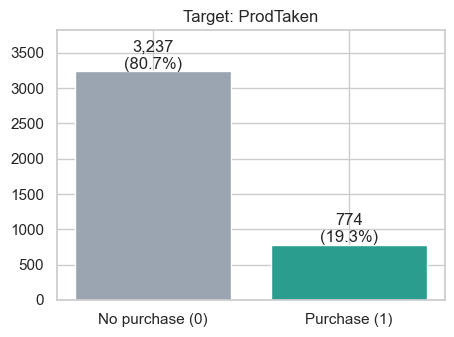

In [14]:
T = config.TARGET
base_rate = df[T].mean() * 100
counts = df[T].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["No purchase (0)", "Purchase (1)"], counts.values, color=["#9aa5b1", "#2a9d8f"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
ax.set_title("Target: ProdTaken"); ax.set_ylim(0, counts.max() * 1.18)
plt.show()

**Observation:** only **19.3 %** of customers bought the package – a ~4 : 1 class imbalance. Plain accuracy would be misleading (always predicting "no purchase" scores ≈ 81 %), so the project uses a *stratified* split, class weights where supported, and judges models with **recall, precision, F1, ROC-AUC and average precision (PR-AUC)**.

### Univariate analysis – numeric features

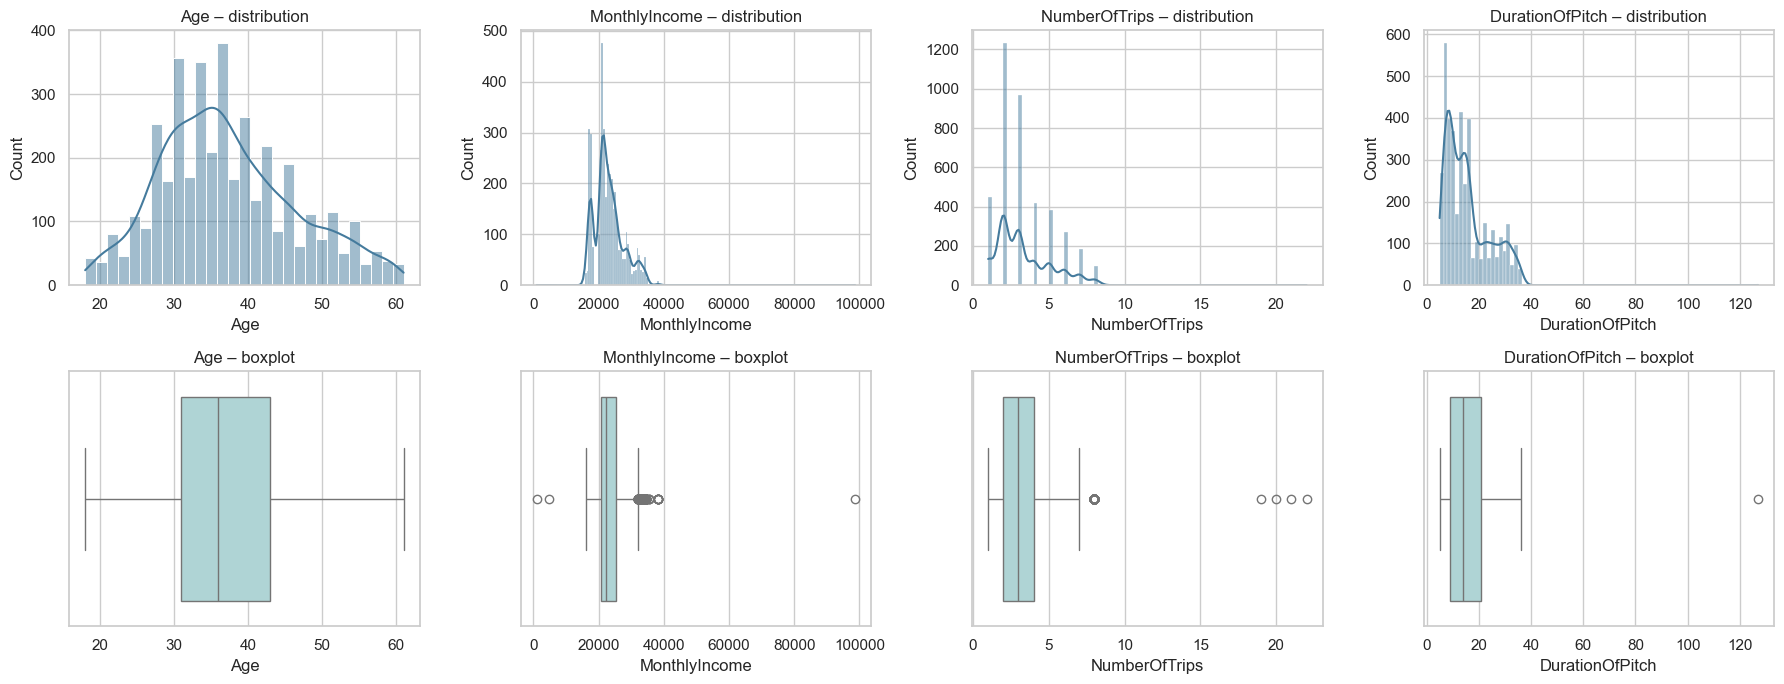

In [15]:
num_plot = ["Age", "MonthlyIncome", "NumberOfTrips", "DurationOfPitch"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(num_plot):
    sns.histplot(df[c], kde=True, ax=axes[0, i], color="#457b9d"); axes[0, i].set_title(f"{c} – distribution")
    sns.boxplot(x=df[c], ax=axes[1, i], color="#a8dadc"); axes[1, i].set_title(f"{c} – boxplot")
plt.tight_layout(); plt.show()

**Observations**
* `Age` is roughly bell-shaped (customers are mostly in their 30s and 40s); `MonthlyIncome` and `NumberOfTrips` are **right-skewed** with a few extreme values (high earners, very frequent travellers).
* `DurationOfPitch` is also skewed, but it is a post-contact attribute and is not used by the model (see 2.4).

### Univariate analysis – categorical features

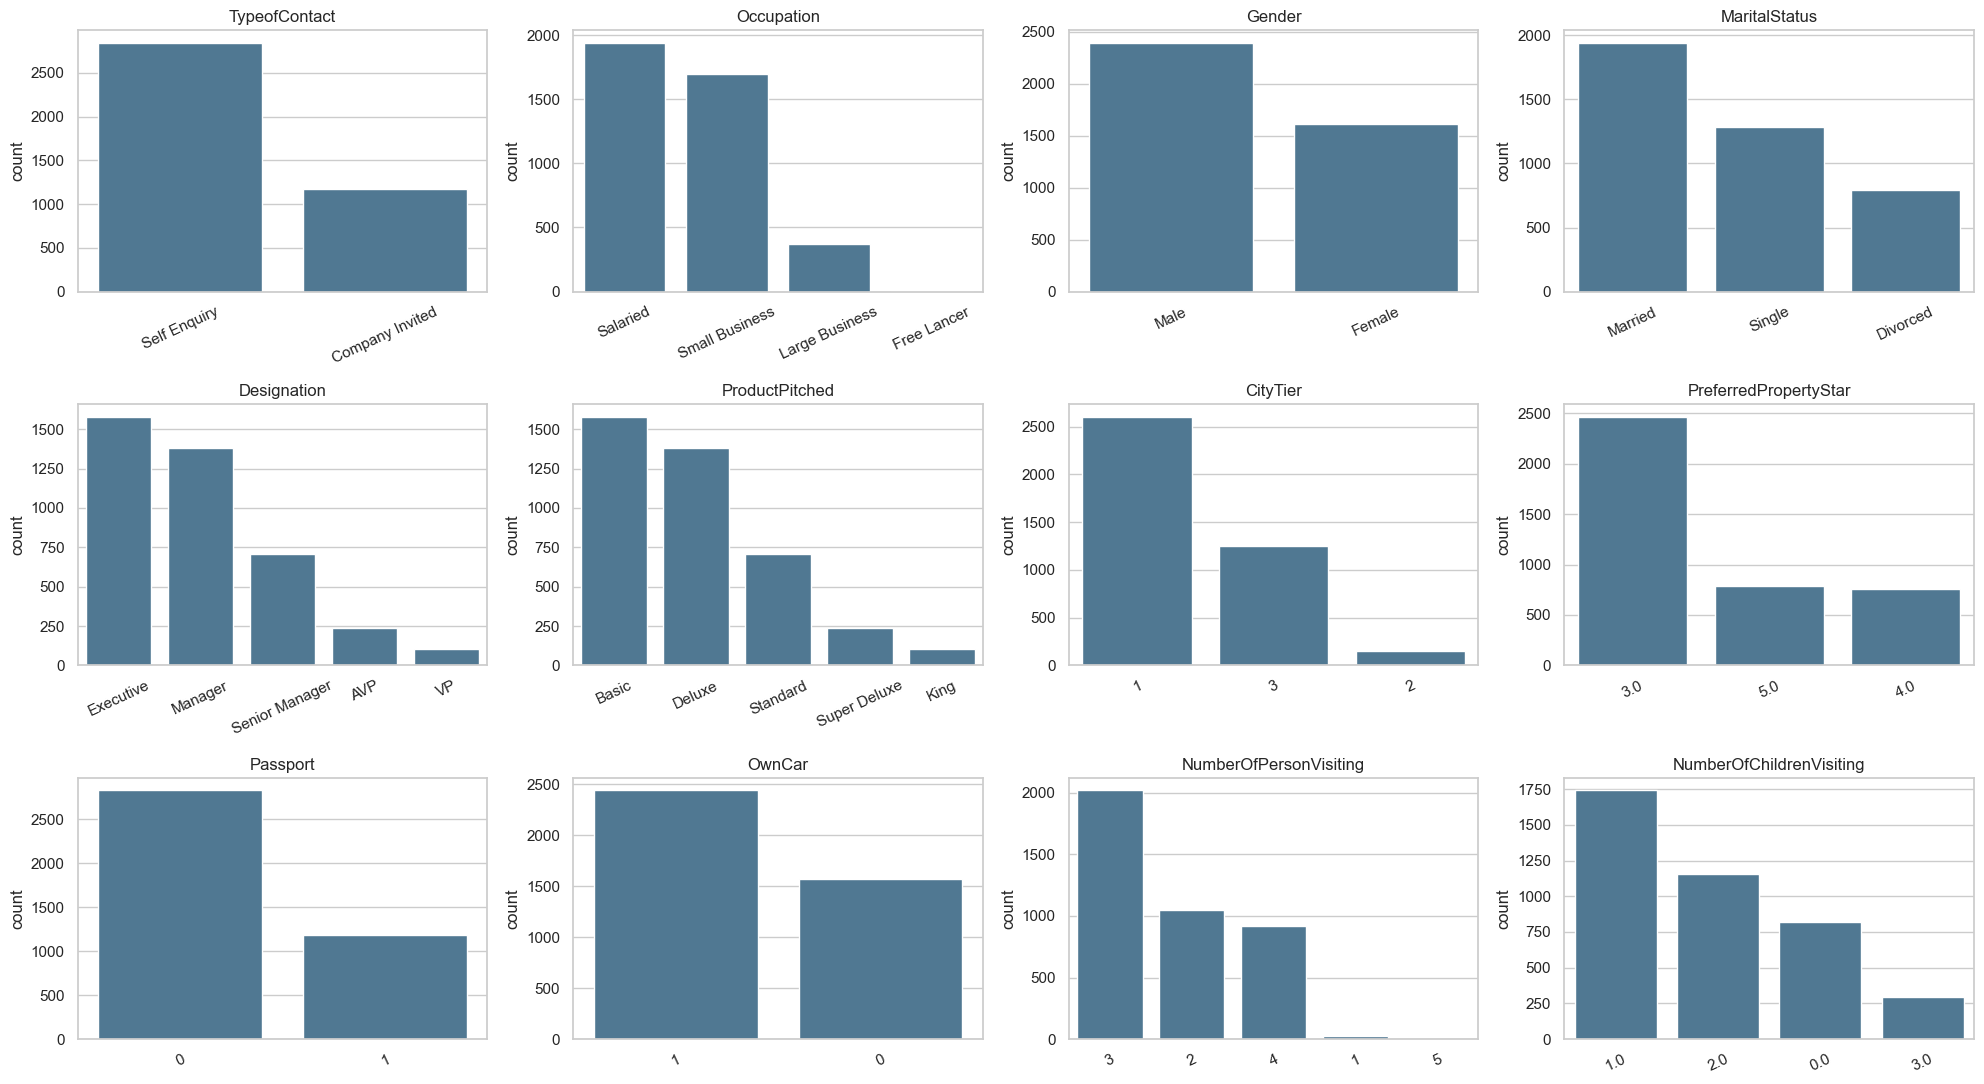

In [16]:
cat_cols = ["TypeofContact", "Occupation", "Gender", "MaritalStatus", "Designation", "ProductPitched",
            "CityTier", "PreferredPropertyStar", "Passport", "OwnCar", "NumberOfPersonVisiting", "NumberOfChildrenVisiting"]
fig, axes = plt.subplots(3, 4, figsize=(20, 11))
for ax, c in zip(axes.ravel(), cat_cols):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=ax, color="#457b9d")
    ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

**Observations**
* Most customers are **Salaried or Small Business** owners, **Self Enquiry** leads outnumber Company Invited ~2.4 : 1, and **City Tier 1** dominates (≈ 65 %).
* **Executive** and **Manager** designations make up the bulk of the base; VP and AVP are small groups.
* About 70 % have no passport; most travel as a party of 2–4 and prefer 3-star properties.

### Bivariate analysis – which customers buy?

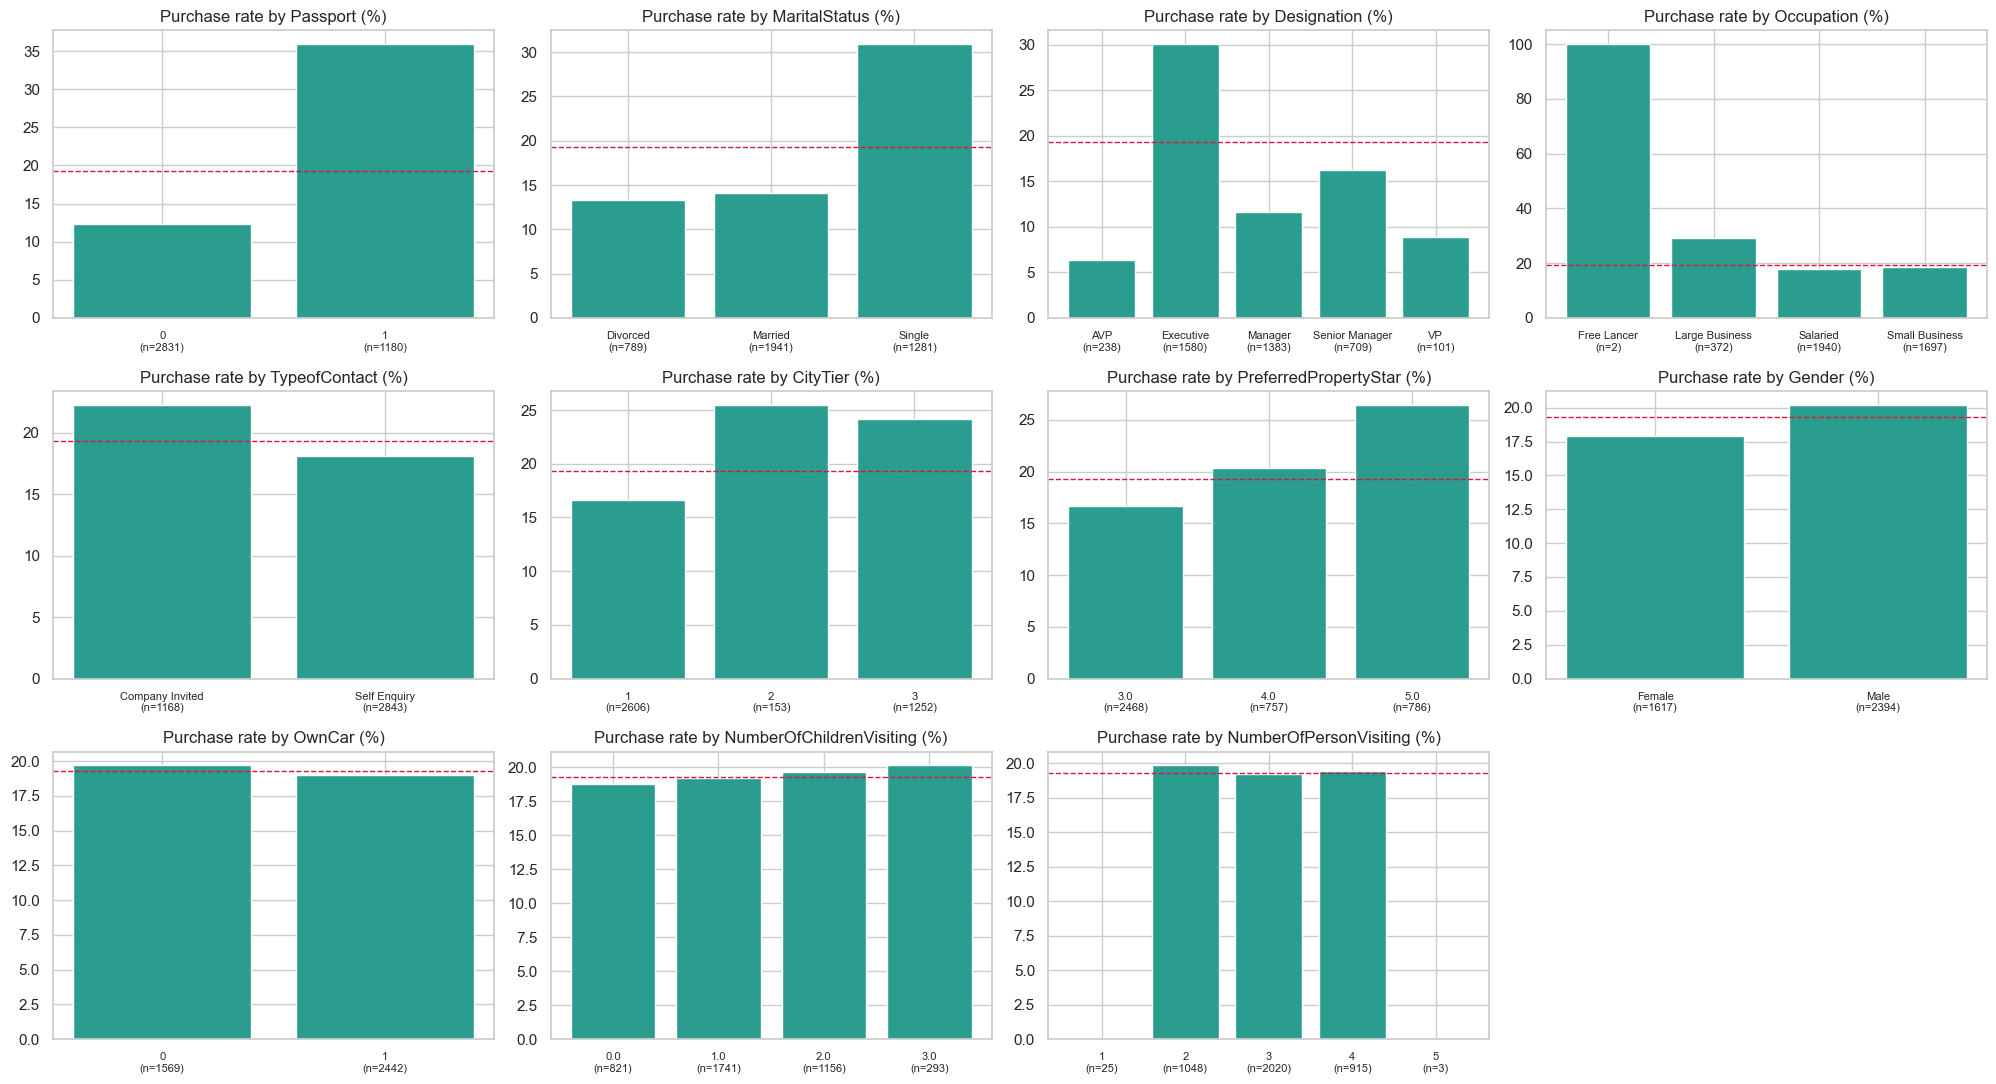

Dashed red line = overall purchase rate (19.3%)


In [17]:
conv_cols = ["Passport", "MaritalStatus", "Designation", "Occupation", "TypeofContact", "CityTier",
             "PreferredPropertyStar", "Gender", "OwnCar", "NumberOfChildrenVisiting", "NumberOfPersonVisiting"]
fig, axes = plt.subplots(3, 4, figsize=(20, 11))
for ax, c in zip(axes.ravel(), conv_cols):
    g = df.groupby(c)[T].agg(["mean", "count"])
    ax.bar([f"{k}\n(n={n})" for k, n in zip(g.index, g["count"])], g["mean"] * 100, color="#2a9d8f")
    ax.axhline(base_rate, ls="--", color="crimson", lw=1)
    ax.set_title(f"Purchase rate by {c} (%)"); ax.tick_params(axis="x", labelsize=8)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()
print(f"Dashed red line = overall purchase rate ({base_rate:.1f}%)")

**Observations (purchase rate vs. the 19.3 % baseline)**
* **Passport** is the strongest single signal: **35.9 %** of passport holders buy vs **12.4 %** without.
* **Single** customers convert at **30.9 %** vs ~14 % for married / divorced customers.
* **Executives** convert at **30.1 %**, versus 11.6 % for Managers, 16.2 % for Senior Managers, 8.9 % for VPs and only 6.3 % for AVPs.
* Customers in **City Tier 2 / 3** (≈ 24–26 %) buy more than Tier 1 (≈ 17 %), and a **5-star** preference (26.5 %) beats 3-star (16.7 %).
* **Company Invited** leads convert slightly better than Self Enquiry (≈ 22 % vs ≈ 18 %).
* The 100 % bar for `Free Lancer` is only **2 customers** – a statistical artefact, not a pattern.
* `Gender`, `OwnCar` and the number of children / people travelling show **no meaningful difference** – they carry little signal (and gender should not drive targeting decisions anyway).

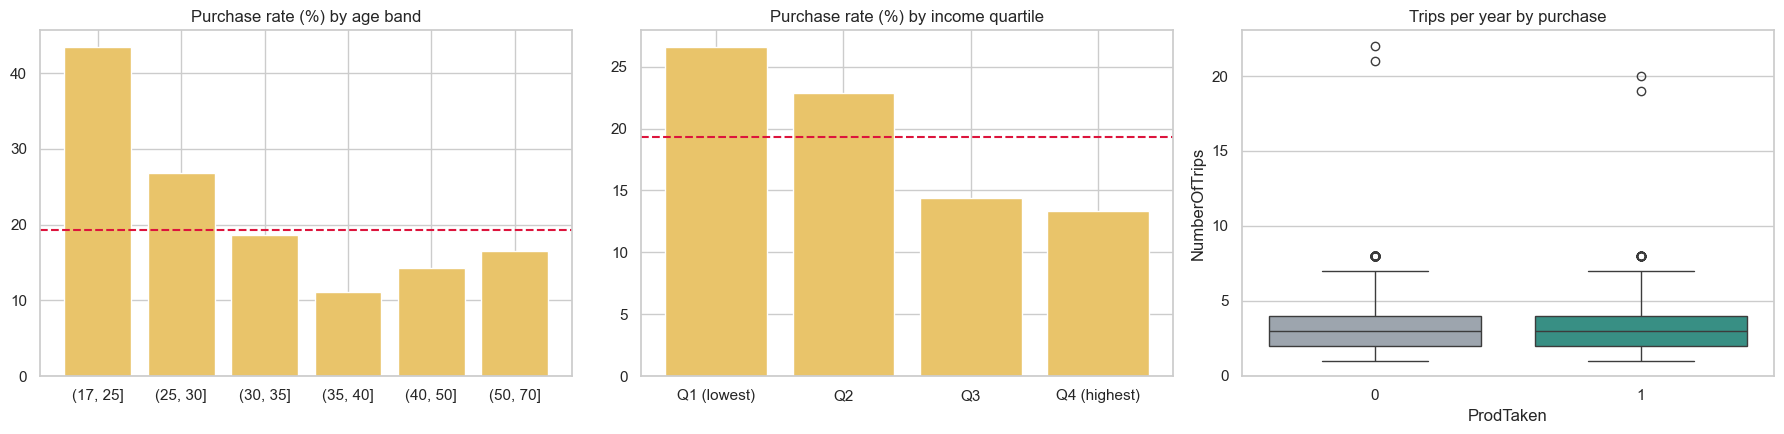

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
age_band = pd.cut(df["Age"], [17, 25, 30, 35, 40, 50, 70]).astype(str)
g = df.groupby(age_band)[T].agg(["mean", "count"]).reindex(["(17, 25]", "(25, 30]", "(30, 35]", "(35, 40]", "(40, 50]", "(50, 70]"])
axes[0].bar(g.index, g["mean"] * 100, color="#e9c46a"); axes[0].set_title("Purchase rate (%) by age band"); axes[0].axhline(base_rate, ls="--", color="crimson")
inc_q = pd.qcut(df["MonthlyIncome"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
g = df.groupby(inc_q, observed=True)[T].mean() * 100
axes[1].bar(g.index.astype(str), g.values, color="#e9c46a"); axes[1].set_title("Purchase rate (%) by income quartile"); axes[1].axhline(base_rate, ls="--", color="crimson")
sns.boxplot(data=df, x=T, y="NumberOfTrips", ax=axes[2], palette=["#9aa5b1", "#2a9d8f"]); axes[2].set_title("Trips per year by purchase")
plt.tight_layout(); plt.show()

**Observations**
* **Younger customers buy far more**: ≈ **44 %** of customers aged ≤ 25 purchase vs ≈ 11 % for ages 35–40.
* **Lower-income customers convert more** (26.6 % in the lowest income quartile vs 13.4 % in the highest) – income and age are positively correlated, so this partly reflects the age effect.
* `NumberOfTrips` is similar for buyers and non-buyers.

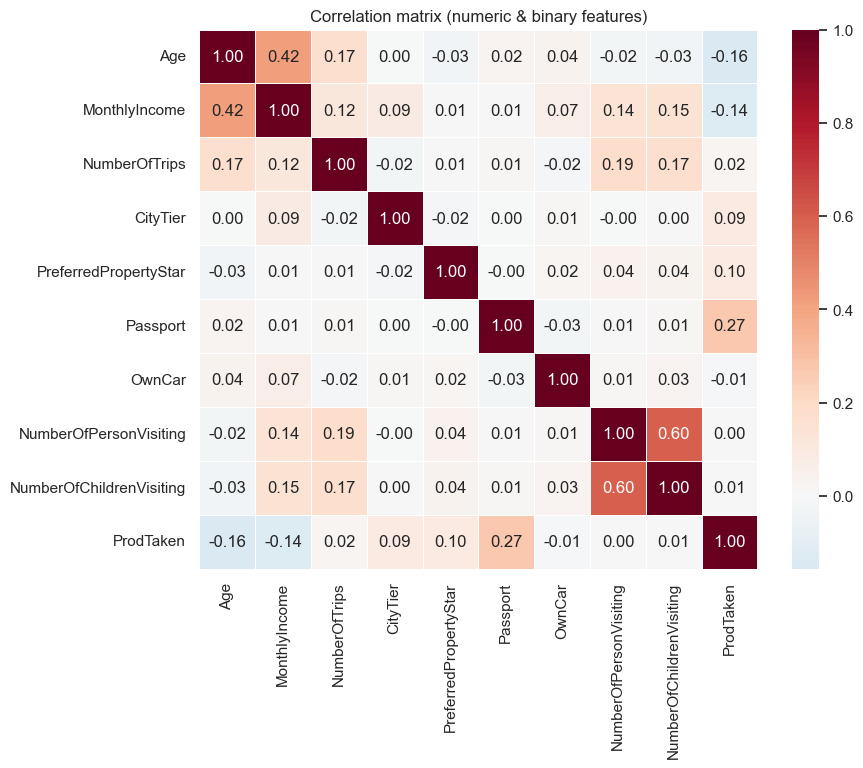

In [19]:
corr_cols = ["Age", "MonthlyIncome", "NumberOfTrips", "CityTier", "PreferredPropertyStar", "Passport", "OwnCar",
             "NumberOfPersonVisiting", "NumberOfChildrenVisiting", T]
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=.5)
plt.title("Correlation matrix (numeric & binary features)"); plt.show()

**Observations:** correlations with the target are modest (strongest: `Passport` ≈ +0.27, `Age` ≈ −0.16, `MonthlyIncome` ≈ −0.14); `Age` and `MonthlyIncome` are moderately correlated (≈ 0.4). No pair of predictors is so correlated that it needs removal. Individually weak signals that combine well (see segments below) favour non-linear tree-based models over a linear one.

In [20]:
seg = (df.groupby(["Passport", "MaritalStatus", "Designation"])[T]
         .agg(purchase_rate="mean", customers="count").query("customers >= 30")
         .sort_values("purchase_rate", ascending=False).head(8))
seg["purchase_rate"] = (seg["purchase_rate"] * 100).round(1)
display(seg)

purchase_rate  customers
Passport MaritalStatus Designation                             
1        Single        Executive                75.7        185
         Married       Executive                49.1        212
         Single        Senior Manager           44.0         50
         Divorced      Executive                41.7         84
         Single        Manager                  41.1        112
0        Single        Executive                30.6        396
1        Divorced      Manager                  21.0         81
                       Senior Manager           19.0         42

**Observation – best segment:** *passport holders who are single executives* buy at **≈ 76 %** (n = 185) – almost 4× the base rate. This is exactly the kind of combination a campaign team should call first, and it shows interactions between features that a tree-based model can learn.

## 2.4 Why the pitch-interaction columns are excluded (leakage check)

In [21]:
display(pd.crosstab(df["Designation"], df["ProductPitched"]))
post = ["DurationOfPitch", "NumberOfFollowups", "PitchSatisfactionScore"]
display(df.groupby(T)[post].mean().round(2).rename(index={0: "No purchase", 1: "Purchase"}))
print("Kept (pre-contact) features:", [c for c in df.columns if c not in config.POST_CONTACT_COLUMNS + [T]])
print("Dropped (post-contact)     :", config.POST_CONTACT_COLUMNS)

ProductPitched,Basic,Deluxe,King,Standard,Super Deluxe
Designation,,,,,
AVP,0,0,0,0,238
Executive,1580,0,0,0,0
Manager,0,1383,0,0,0
Senior Manager,0,0,0,709,0
VP,0,0,101,0,0


,DurationOfPitch,NumberOfFollowups,PitchSatisfactionScore
ProdTaken,,,
No purchase,15.27,3.68,3.00
Purchase,16.96,3.98,3.19


Kept (pre-contact) features: ['Age', 'TypeofContact', 'CityTier', 'Occupation', 'Gender', 'NumberOfPersonVisiting', 'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport', 'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome']
Dropped (post-contact)     : ['DurationOfPitch', 'NumberOfFollowups', 'PitchSatisfactionScore', 'ProductPitched']


**Observations**
* `ProductPitched` maps **one-to-one onto `Designation`** (Executive→Basic, Manager→Deluxe, Senior Manager→Standard, AVP→Super Deluxe, VP→King): it is the sales team's *response* to the customer's designation, so it adds nothing new and exists only after the pitch.
* `DurationOfPitch`, `NumberOfFollowups` and `PitchSatisfactionScore` only exist **after** the salesperson has spoken to the customer, and they differ little between buyers and non-buyers (e.g. mean follow-ups 3.7 vs 4.0). Including them would make the model unusable for its real job (choosing whom to call) while adding almost no accuracy.
* → The model uses **14 pre-contact features** only.

## 2.5 Train / test split, save and re-upload to the Hugging Face dataset repo

`prep.py` was written in section 0.1 (the EDA above already imports its cleaning function); here it is executed.

In [22]:
!"{PY}" tourism_project/model_building/prep.py

tourism.csv: 100%|██████████████████████████| 477k/477k [00:00<00:00, 7.01MB/s]
Loaded raw data from Hugging Face dataset repo: CasioThief/visit-with-us-tourism-data
{
  "raw_rows": 4128,
  "raw_columns": 21,
  "rows_after_cleaning": 4011,
  "duplicates_removed": 117,
  "pre_contact_features_kept": [
    "Age",
    "TypeofContact",
    "CityTier",
    "Occupation",
    "Gender",
    "NumberOfPersonVisiting",
    "PreferredPropertyStar",
    "MaritalStatus",
    "NumberOfTrips",
    "Passport",
    "OwnCar",
    "NumberOfChildrenVisiting",
    "Designation",
    "MonthlyIncome"
  ],
  "post_contact_features_dropped": [
    "DurationOfPitch",
    "NumberOfFollowups",
    "PitchSatisfactionScore",
    "ProductPitched"
  ],
  "identifier_columns_dropped": [
    "Unnamed: 0",
    "CustomerID"
  ],
  "train_rows": 3208,
  "test_rows": 803,
  "train_positive_rate": 0.193,
  "test_positive_rate": 0.193,
  "missing_values_remaining": 0
}
Train/test files uploaded to https://huggingface.co/datas

In [23]:
summary = json.loads((config.DATA_DIR / "prep_summary.json").read_text())
display(pd.Series({k: (", ".join(v) if isinstance(v, list) else v) for k, v in summary.items()}, name="value").to_frame())
Xtrain = pd.read_csv(config.DATA_DIR / "Xtrain.csv"); ytrain = pd.read_csv(config.DATA_DIR / "ytrain.csv")
print("Xtrain", Xtrain.shape, "| Xtest", pd.read_csv(config.DATA_DIR / "Xtest.csv").shape)
display(Xtrain.head())

,value
raw_rows,4128
raw_columns,21
rows_after_cleaning,4011
duplicates_removed,117
pre_contact_features_kept,"Age, TypeofContact, CityTier, Occupation, Gend..."
post_contact_features_dropped,"DurationOfPitch, NumberOfFollowups, PitchSatis..."
identifier_columns_dropped,"Unnamed: 0, CustomerID"
train_rows,3208
test_rows,803
train_positive_rate,0.193


Xtrain (3208, 14) | Xtest (803, 14)


,Age,TypeofContact,CityTier,Occupation,Gender,NumberOfPersonVisiting,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,31.0,Self Enquiry,1,Salaried,Male,2,3.0,Divorced,4.0,1,1,1.0,Executive,17356.0
1,38.0,Self Enquiry,1,Small Business,Female,4,4.0,Divorced,7.0,0,1,1.0,Manager,23455.0
2,28.0,Self Enquiry,1,Salaried,Male,3,3.0,Divorced,3.0,0,1,2.0,Executive,21217.0
3,37.0,Self Enquiry,1,Salaried,Female,3,5.0,Married,2.0,0,1,0.0,Executive,18034.0
4,46.0,Self Enquiry,3,Salaried,Female,3,3.0,Single,2.0,0,1,1.0,Manager,23528.0


**Observation:** an 80 / 20 **stratified** split keeps the purchase rate at 19.3 % in both sets; train/test files were saved locally and uploaded to the dataset repo, so the training job (and CI) can fetch exactly the same split.

# 3. Model Training and Registration with Experimentation Tracking
**Approach**
* Pipeline = `ColumnTransformer` (median-impute + scale numeric; most-frequent-impute + one-hot categorical) → classifier.
* Four candidate families: **Logistic Regression, Decision Tree, Random Forest, Gradient Boosting**, each tuned with **5-fold stratified `GridSearchCV`**; class imbalance handled with class weights.
* **Every grid-search trial is logged to MLflow** (parameters + CV metrics) as a nested run; each family also logs its best parameters and train / test metrics.
* The best model is **selected on cross-validated average precision (training data only)** – the test set is never used to choose a model.
* The decision **threshold is tuned on out-of-fold training predictions** (maximum F1) because 0.5 is a poor cut-off for a 19 %-positive problem.
* The best model + threshold are saved as one `joblib` bundle and **registered on the Hugging Face Model Hub**.

In [24]:
%%writefile tourism_project/model_building/train.py
"""Step 3 - Model training with hyper-parameter tuning, MLflow tracking and HF model registration."""
import json
import os
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import mlflow  # noqa: E402
import mlflow.sklearn  # noqa: E402,F401
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import sklearn  # noqa: E402
from sklearn.base import clone  # noqa: E402
from sklearn.compose import ColumnTransformer  # noqa: E402
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier  # noqa: E402
from sklearn.impute import SimpleImputer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import (  # noqa: E402
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict  # noqa: E402
from sklearn.pipeline import Pipeline  # noqa: E402
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # noqa: E402
from sklearn.tree import DecisionTreeClassifier  # noqa: E402

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
import config  # noqa: E402
from pipeline_utils import retry  # noqa: E402

warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_HTTP_REQUEST_MAX_RETRIES", "2")
os.environ.setdefault("MLFLOW_HTTP_REQUEST_BACKOFF_FACTOR", "1")

RS = config.RANDOM_STATE


# ----------------------------------------------------------------------------- data
def load_split():
    token = os.getenv("HF_TOKEN")
    frames = {}
    for name in ["Xtrain.csv", "Xtest.csv", "ytrain.csv", "ytest.csv"]:
        path = config.DATA_DIR / name
        if token:
            try:
                from huggingface_hub import hf_hub_download

                path = hf_hub_download(
                    repo_id=config.DATASET_REPO, filename=name, repo_type="dataset", token=token
                )
            except Exception as exc:
                print(f"Could not download {name} from the Hub ({type(exc).__name__}); using local copy.")
        if not Path(path).exists():
            sys.exit(f"{name} not found. Run prep.py first.")
        frames[name] = pd.read_csv(path)
    return (
        frames["Xtrain.csv"],
        frames["Xtest.csv"],
        frames["ytrain.csv"].iloc[:, 0],
        frames["ytest.csv"].iloc[:, 0],
    )


def build_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    numeric = X.select_dtypes(include="number").columns.tolist()
    categorical = X.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer(
        [
            ("numeric", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), numeric),
            (
                "categorical",
                Pipeline(
                    [
                        ("imp", SimpleImputer(strategy="most_frequent")),
                        ("ohe", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                categorical,
            ),
        ]
    )


# ------------------------------------------------------------------------- helpers
def evaluate(y_true, proba, threshold=0.5) -> dict:
    pred = (proba >= threshold).astype(int)
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, proba)),
        "average_precision": float(average_precision_score(y_true, proba)),
    }


def setup_mlflow() -> str:
    uri = os.getenv("MLFLOW_TRACKING_URI", config.MLFLOW_DEFAULT_URI)
    try:
        mlflow.set_tracking_uri(uri)
        mlflow.set_experiment(config.EXPERIMENT_NAME)
    except Exception as exc:
        print(f"MLflow server at {uri} not reachable ({type(exc).__name__}); using local SQLite store.")
        uri = config.MLFLOW_DEFAULT_URI
        mlflow.set_tracking_uri(uri)
        mlflow.set_experiment(config.EXPERIMENT_NAME)
    print("MLflow tracking URI:", uri)
    return uri


def safe_log_artifact(path):
    try:
        mlflow.log_artifact(str(path))
    except Exception as exc:  # artifact store problems must not kill the pipeline
        print(f"  (could not log artifact {Path(path).name}: {type(exc).__name__})")


def clean_names(names):
    return [n.split("__", 1)[-1] for n in names]


def get_candidates():
    return {
        "logistic_regression": (
            LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RS),
            {"model__C": [0.05, 0.1, 0.5, 1, 5, 10]},
        ),
        "decision_tree": (
            DecisionTreeClassifier(class_weight="balanced", random_state=RS),
            {"model__max_depth": [4, 6, 8, 12], "model__min_samples_leaf": [1, 5, 10, 20]},
        ),
        "random_forest": (
            RandomForestClassifier(class_weight="balanced_subsample", random_state=RS, n_jobs=1),
            {
                "model__n_estimators": [150, 300],
                "model__max_depth": [8, 12, None],
                "model__min_samples_leaf": [1, 3],
            },
        ),
        "gradient_boosting": (
            GradientBoostingClassifier(random_state=RS),
            {
                "model__n_estimators": [100, 200],
                "model__learning_rate": [0.05, 0.1],
                "model__max_depth": [2, 3, 4],
            },
        ),
    }


def track_family(name, gs, scoring, m_test, m_train):
    """Log every grid-search trial plus the family summary. Tracking problems never stop the pipeline."""
    try:
        with mlflow.start_run(run_name=name):
            mlflow.set_tag("model_family", name)
            for i, params in enumerate(gs.cv_results_["params"]):
                with mlflow.start_run(run_name=f"{name}-trial-{i:02d}", nested=True):
                    mlflow.log_params({k: str(v) for k, v in params.items()})
                    mlflow.log_metrics(
                        {f"cv_{m}": float(gs.cv_results_[f"mean_test_{m}"][i]) for m in scoring}
                    )
            mlflow.log_params({f"best_{k}": str(v) for k, v in gs.best_params_.items()})
            mlflow.log_metrics({f"cv_best_{m}": float(gs.cv_results_[f"mean_test_{m}"][gs.best_index_]) for m in scoring})
            mlflow.log_metrics({f"test_{k}": v for k, v in m_test.items()})
            mlflow.log_metrics({f"train_{k}": v for k, v in m_train.items()})
    except Exception as exc:  # noqa: BLE001
        print(f"  (MLflow logging for {name} failed: {type(exc).__name__}: {exc}) - continuing")
        while mlflow.active_run():  # make sure no half-open run blocks the next family
            mlflow.end_run()


# ------------------------------------------------------------------------- main
def main():
    config.ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    Xtrain, Xtest, ytrain, ytest = load_split()
    print(f"Train: {Xtrain.shape}  Test: {Xtest.shape}  Positive rate (train): {ytrain.mean():.3f}")
    print("Features:", Xtrain.columns.tolist())
    setup_mlflow()

    scoring = {
        "roc_auc": "roc_auc",
        "average_precision": "average_precision",
        "f1": "f1",
        "recall": "recall",
        "precision": "precision",
    }
    cv = StratifiedKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=RS)

    rows, tuned = [], {}
    for name, (estimator, grid) in get_candidates().items():
        print(f"\nTuning {name} ({np.prod([len(v) for v in grid.values()])} combinations x {config.CV_FOLDS} folds)")
        pipe = Pipeline([("preprocess", build_preprocessor(Xtrain)), ("model", estimator)])
        gs = GridSearchCV(pipe, grid, scoring=scoring, refit="average_precision", cv=cv, n_jobs=-1)
        gs.fit(Xtrain, ytrain)
        best = gs.best_estimator_
        tuned[name] = gs

        train_proba = best.predict_proba(Xtrain)[:, 1]
        test_proba = best.predict_proba(Xtest)[:, 1]
        m_train, m_test = evaluate(ytrain, train_proba), evaluate(ytest, test_proba)

        track_family(name, gs, scoring, m_test, m_train)

        rows.append(
            {
                "model": name,
                "cv_average_precision": gs.best_score_,
                "cv_roc_auc": float(gs.cv_results_["mean_test_roc_auc"][gs.best_index_]),
                "cv_f1": float(gs.cv_results_["mean_test_f1"][gs.best_index_]),
                "test_accuracy": m_test["accuracy"],
                "test_precision": m_test["precision"],
                "test_recall": m_test["recall"],
                "test_f1": m_test["f1"],
                "test_roc_auc": m_test["roc_auc"],
                "train_roc_auc": m_train["roc_auc"],
                "best_params": json.dumps({k: str(v) for k, v in gs.best_params_.items()}),
            }
        )
        print(f"  best CV average-precision: {gs.best_score_:.4f}  | test ROC-AUC: {m_test['roc_auc']:.4f}")

    comparison = pd.DataFrame(rows).sort_values("cv_average_precision", ascending=False).reset_index(drop=True)
    comparison.to_csv(config.ARTIFACT_DIR / "model_comparison.csv", index=False)

    # ---- model selection uses cross-validation on TRAIN only (the test set is not used to choose)
    best_name = comparison.loc[0, "model"]
    best_gs = tuned[best_name]
    best_model = best_gs.best_estimator_
    print("\nSelected model:", best_name, best_gs.best_params_)

    # ---- decision threshold chosen from out-of-fold predictions on TRAIN (maximise F1)
    oof = cross_val_predict(clone(best_model), Xtrain, ytrain, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    grid_t = np.round(np.arange(0.10, 0.91, 0.01), 2)
    f1s = [f1_score(ytrain, (oof >= t).astype(int), zero_division=0) for t in grid_t]
    threshold = float(grid_t[int(np.argmax(f1s))])
    print(f"Decision threshold (max OOF F1 on train): {threshold:.2f}")

    test_proba = best_model.predict_proba(Xtest)[:, 1]
    test_pred = (test_proba >= threshold).astype(int)
    metrics_tuned = evaluate(ytest, test_proba, threshold)
    metrics_default = evaluate(ytest, test_proba, 0.5)
    cm = confusion_matrix(ytest, test_pred)
    print("\nTest metrics @ tuned threshold:", {k: round(v, 4) for k, v in metrics_tuned.items()})
    print("Test metrics @ 0.50 threshold :", {k: round(v, 4) for k, v in metrics_default.items()})
    print("Confusion matrix [[TN, FP], [FN, TP]]:", cm.tolist())
    print(classification_report(ytest, test_pred, zero_division=0))

    # ---- plots
    plot_paths = []
    try:
        fig, ax = plt.subplots(figsize=(4.5, 4))
        ax.imshow(cm, cmap="Blues")
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, int(v), ha="center", va="center", fontsize=14, color="black")
        ax.set_xticks([0, 1], ["No purchase", "Purchase"])
        ax.set_yticks([0, 1], ["No purchase", "Purchase"])
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title(f"Confusion matrix (threshold {threshold:.2f})")
        p = config.ARTIFACT_DIR / "confusion_matrix.png"
        fig.tight_layout()
        fig.savefig(p, dpi=130)
        plt.close(fig)
        plot_paths.append(p)

        fig, ax = plt.subplots(1, 2, figsize=(10, 4))
        fpr, tpr, _ = roc_curve(ytest, test_proba)
        ax[0].plot(fpr, tpr, label=f"AUC = {metrics_tuned['roc_auc']:.3f}")
        ax[0].plot([0, 1], [0, 1], "--", color="grey")
        ax[0].set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate")
        ax[0].legend()
        ax[1].plot(grid_t, f1s, color="tab:green")
        ax[1].axvline(threshold, ls="--", color="tab:red", label=f"chosen = {threshold:.2f}")
        ax[1].set(title="F1 vs threshold (out-of-fold, train)", xlabel="Threshold", ylabel="F1")
        ax[1].legend()
        p = config.ARTIFACT_DIR / "roc_and_threshold.png"
        fig.tight_layout()
        fig.savefig(p, dpi=130)
        plt.close(fig)
        plot_paths.append(p)

        names = clean_names(best_model.named_steps["preprocess"].get_feature_names_out())
        mdl = best_model.named_steps["model"]
        if hasattr(mdl, "feature_importances_"):
            vals = mdl.feature_importances_
        elif hasattr(mdl, "coef_"):
            vals = np.abs(mdl.coef_.ravel())
        else:
            vals = None
        if vals is not None:
            imp = pd.Series(vals, index=names).sort_values(ascending=False)
            imp.to_csv(config.ARTIFACT_DIR / "feature_importance.csv", header=["importance"])
            top = imp.head(15)[::-1]
            fig, ax = plt.subplots(figsize=(7, 5))
            ax.barh(top.index, top.values, color="tab:blue")
            ax.set_title(f"Top 15 features - {best_name}")
            p = config.ARTIFACT_DIR / "feature_importance.png"
            fig.tight_layout()
            fig.savefig(p, dpi=130)
            plt.close(fig)
            plot_paths.append(p)
    except Exception as exc:
        print("Plotting skipped:", type(exc).__name__, exc)

    # ---- persist model bundle + evaluation report
    bundle = {
        "pipeline": best_model,
        "threshold": threshold,
        "features": Xtrain.columns.tolist(),
        "model_name": best_name,
        "best_params": {k: str(v) for k, v in best_gs.best_params_.items()},
        "metrics_test_tuned_threshold": metrics_tuned,
        "sklearn_version": sklearn.__version__,
        "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    model_path = config.ARTIFACT_DIR / config.MODEL_FILE
    joblib.dump(bundle, model_path)

    report = {
        "selected_model": best_name,
        "best_params": bundle["best_params"],
        "threshold": threshold,
        "features": bundle["features"],
        "metrics_test_tuned_threshold": metrics_tuned,
        "metrics_test_default_threshold_0.5": metrics_default,
        "confusion_matrix_[[TN,FP],[FN,TP]]": cm.tolist(),
        "train_rows": int(len(Xtrain)),
        "test_rows": int(len(Xtest)),
        "positive_rate_train": float(ytrain.mean()),
        "sklearn_version": sklearn.__version__,
    }
    eval_path = config.ARTIFACT_DIR / "evaluation.json"
    eval_path.write_text(json.dumps(report, indent=2))

    # ---- final MLflow run for the registered model
    try:
        with mlflow.start_run(run_name="best-model-final"):
            mlflow.set_tag("selected_model", best_name)
            mlflow.log_params({"model": best_name, "threshold": threshold, **{f"best_{k}": v for k, v in bundle["best_params"].items()}})
            mlflow.log_metrics({f"final_test_{k}": v for k, v in metrics_tuned.items()})
            for p in [model_path, eval_path, config.ARTIFACT_DIR / "model_comparison.csv", *plot_paths]:
                safe_log_artifact(p)
            try:
                mlflow.sklearn.log_model(best_model, "model")
            except Exception as exc:
                print(f"  (mlflow model flavour not logged: {type(exc).__name__})")
    except Exception as exc:  # noqa: BLE001
        print(f"  (final MLflow run failed: {type(exc).__name__}: {exc}) - continuing to model registration")
        while mlflow.active_run():
            mlflow.end_run()

    # ---- register the model on the Hugging Face Model Hub
    token = os.getenv("HF_TOKEN")
    if token:
        from huggingface_hub import HfApi

        api = HfApi(token=token)
        retry(
            lambda: api.create_repo(repo_id=config.MODEL_REPO, repo_type="model", private=False, exist_ok=True),
            what="create model repo",
        )
        card = (
            "---\nlibrary_name: sklearn\ntags:\n- tabular-classification\n- tourism\n---\n"
            f"# Wellness Tourism purchase model\n\nSelected model: **{best_name}**  \n"
            f"Decision threshold: **{threshold:.2f}**  \n"
            f"Test ROC-AUC: **{metrics_tuned['roc_auc']:.3f}**, recall: **{metrics_tuned['recall']:.3f}**, "
            f"precision: **{metrics_tuned['precision']:.3f}**, F1: **{metrics_tuned['f1']:.3f}**\n\n"
            "Uses only pre-contact customer attributes. Load with `joblib.load` "
            f"(scikit-learn {sklearn.__version__}).\n"
        )
        retry(
            lambda: api.upload_file(
                path_or_fileobj=card.encode(), path_in_repo="README.md", repo_id=config.MODEL_REPO, repo_type="model"
            ),
            what="upload model card",
        )
        for path in [model_path, eval_path]:
            retry(
                lambda path=path: api.upload_file(
                    path_or_fileobj=str(path),
                    path_in_repo=path.name,
                    repo_id=config.MODEL_REPO,
                    repo_type="model",
                    commit_message=f"Register {best_name} model",
                ),
                what=f"upload {path.name}",
            )
        if not api.file_exists(repo_id=config.MODEL_REPO, filename=config.MODEL_FILE, repo_type="model"):
            sys.exit("Upload finished but the model file is not visible in the model repo - check token permissions.")
        print("Model registered:", f"https://huggingface.co/{config.MODEL_REPO}")
    else:
        print("HF_TOKEN not set - model saved locally only:", model_path)


if __name__ == "__main__":
    main()

Overwriting tourism_project/model_building/train.py


In [25]:
!"{PY}" tourism_project/model_building/train.py

Xtrain.csv: 100%|███████████████████████████| 264k/264k [00:00<00:00, 3.50MB/s]
Xtest.csv: 100%|██████████████████████████| 66.3k/66.3k [00:00<00:00, 55.6MB/s]
ytrain.csv: 100%|█████████████████████████| 6.43k/6.43k [00:00<00:00, 6.36MB/s]
ytest.csv: 100%|██████████████████████████| 1.62k/1.62k [00:00<00:00, 3.32MB/s]
Train: (3208, 14)  Test: (803, 14)  Positive rate (train): 0.193
Features: ['Age', 'TypeofContact', 'CityTier', 'Occupation', 'Gender', 'NumberOfPersonVisiting', 'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport', 'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome']
2026/10/17 20:56:08 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/17 20:56:08 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step
I

In [26]:
art = config.ARTIFACT_DIR
comp = pd.read_csv(art / "model_comparison.csv")
display(comp.drop(columns="best_params").round(3))
print("Best hyper-parameters per model:")
for _, r in comp.iterrows():
    print(f"  {r['model']:<20}", r["best_params"])

,model,cv_average_precision,cv_roc_auc,cv_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,train_roc_auc
0,random_forest,0.781,0.928,0.612,0.890,0.885,0.497,0.636,0.922,1.000
1,gradient_boosting,0.722,0.880,0.624,0.887,0.856,0.497,0.629,0.872,0.984
2,decision_tree,0.564,0.807,0.536,0.748,0.415,0.742,0.532,0.806,0.933
3,logistic_regression,0.562,0.804,0.526,0.721,0.376,0.677,0.484,0.787,0.810


Best hyper-parameters per model:
  random_forest        {"model__max_depth": "None", "model__min_samples_leaf": "1", "model__n_estimators": "300"}
  gradient_boosting    {"model__learning_rate": "0.1", "model__max_depth": "4", "model__n_estimators": "200"}
  decision_tree        {"model__max_depth": "8", "model__min_samples_leaf": "5"}
  logistic_regression  {"model__C": "0.05"}


Selected model : random_forest | threshold: 0.31


,threshold = tuned,threshold = 0.50
accuracy,0.8892,0.8904
precision,0.7012,0.8851
recall,0.7419,0.4968
f1,0.7210,0.6364
roc_auc,0.9216,0.9216
average_precision,0.8022,0.8022


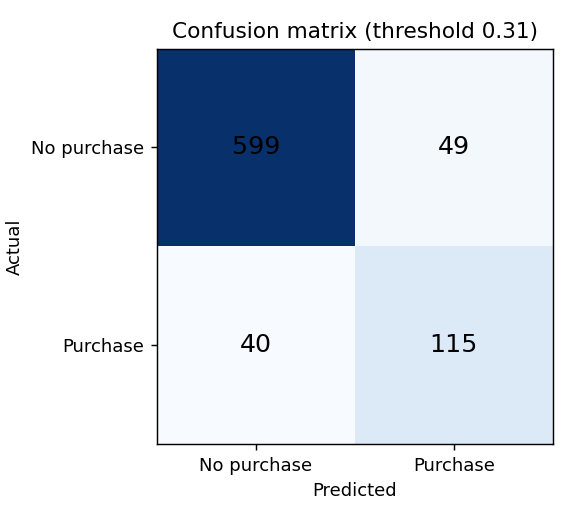

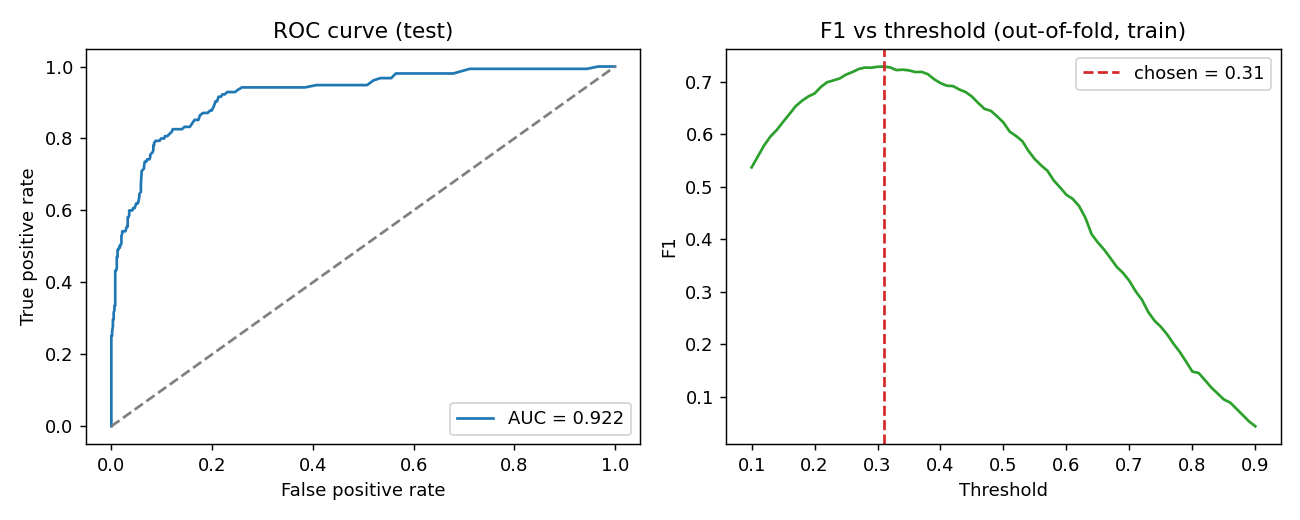

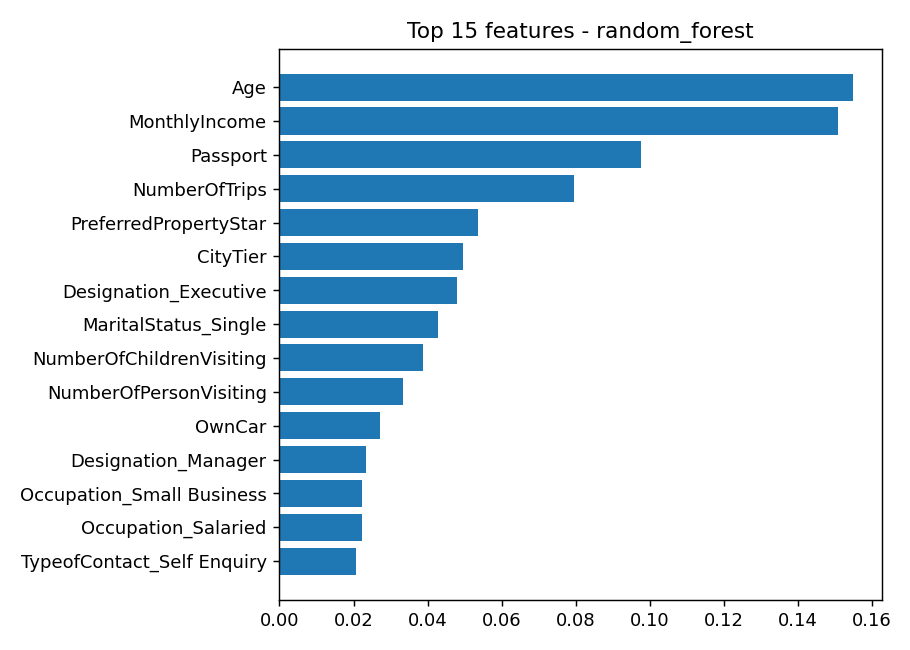

In [27]:
report = json.loads((art / "evaluation.json").read_text())
print("Selected model :", report["selected_model"], "| threshold:", report["threshold"])
display(pd.DataFrame({"threshold = tuned": report["metrics_test_tuned_threshold"],
                      "threshold = 0.50": report["metrics_test_default_threshold_0.5"]}).round(4))
for f in ["confusion_matrix.png", "roc_and_threshold.png", "feature_importance.png"]:
    if (art / f).exists():
        display(Image(filename=str(art / f), width=760))

**Observations**
* **Tree ensembles clearly beat the linear and single-tree baselines** (Random Forest / Gradient Boosting reach a much higher ROC-AUC and PR-AUC than Logistic Regression). The purchase pattern is made of **feature interactions** (e.g. passport × single × executive) that a linear model cannot express.
* The training ROC-AUC of the Random Forest is ≈ 1.0 (it memorises the training data) but its **cross-validated and test ROC-AUC agree closely**, so the generalisation estimate is trustworthy; selection used CV only.
* **Threshold tuning matters:** at 0.50 the model is precise but misses more than half of the buyers; at the tuned threshold recall rises sharply for a moderate loss in precision – the right trade-off when the cost of a missed buyer (lost revenue) exceeds the cost of one extra sales call.
* Most influential features: **Age, MonthlyIncome, Passport, NumberOfTrips** – consistent with the EDA findings.

### MLflow experiment tracking

In [28]:
import mlflow
mlflow.set_tracking_uri(config.MLFLOW_DEFAULT_URI)
runs = mlflow.search_runs(experiment_names=[config.EXPERIMENT_NAME])
parent_col = "tags.mlflow.parentRunId"
top = runs[runs[parent_col].isna()] if parent_col in runs.columns else runs
cols = [c for c in ["tags.mlflow.runName", "metrics.cv_best_average_precision", "metrics.cv_best_roc_auc",
                    "metrics.test_roc_auc", "metrics.test_recall", "metrics.final_test_f1", "metrics.final_test_recall"] if c in top.columns]
print(f"Total runs logged in experiment '{config.EXPERIMENT_NAME}': {len(runs)}  (parent runs: {len(top)})")
display(top[cols].round(3))

Total runs logged in experiment 'visit-with-us-wellness-tourism': 51  (parent runs: 5)


,tags.mlflow.runName,metrics.cv_best_average_precision,metrics.cv_best_roc_auc,metrics.test_roc_auc,metrics.test_recall,metrics.final_test_f1,metrics.final_test_recall
0,best-model-final,NaN,NaN,NaN,NaN,0.721,0.742
13,gradient_boosting,0.722,0.880,0.872,0.497,NaN,NaN
26,random_forest,0.781,0.928,0.922,0.497,NaN,NaN
43,decision_tree,0.564,0.807,0.806,0.742,NaN,NaN
50,logistic_regression,0.562,0.804,0.787,0.677,NaN,NaN


To explore the runs interactively, open a **Terminal** in the project root and run (then open <http://127.0.0.1:5000> and take a screenshot for the submission):

```bash
source .venv/bin/activate
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

# 4. Model Deployment
The app is packaged as a **Docker container** that serves a **Streamlit** UI on port 8501 and downloads the registered model from the Hugging Face Model Hub at start-up.

## 4.1 Dockerfile

In [29]:
%%writefile tourism_project/deployment/Dockerfile
FROM python:3.11-slim

# Hugging Face Spaces runs containers as a non-root user with uid 1000
RUN useradd -m -u 1000 user
ENV HOME=/home/user \
    PATH=/home/user/.local/bin:$PATH \
    STREAMLIT_BROWSER_GATHER_USAGE_STATS=false \
    PYTHONUNBUFFERED=1 \
    PIP_DISABLE_PIP_VERSION_CHECK=1

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY --chown=user . /app
USER user

EXPOSE 8501

HEALTHCHECK --interval=30s --timeout=5s --start-period=60s --retries=3 \
  CMD python -c "import urllib.request; urllib.request.urlopen('http://127.0.0.1:8501/_stcore/health', timeout=4)" || exit 1

CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false", "--server.enableCORS=false"]

Overwriting tourism_project/deployment/Dockerfile


## 4.2 Streamlit app (`app.py`)
The form only asks for information that is known **before** contact, builds a one-row DataFrame in the model's feature order and returns the purchase probability with a High / Medium / Low priority.

In [30]:
%%writefile tourism_project/deployment/app.py
"""Streamlit front-end for the Visit with Us Wellness Tourism purchase predictor."""
import json
import os
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

MODEL_FILE = "tourism_model_v1.joblib"
HERE = Path(__file__).resolve().parent

st.set_page_config(page_title="Visit with Us | Wellness Tourism", page_icon="🌿", layout="wide")


@st.cache_resource(show_spinner="Loading model...")
def load_bundle():
    """Return (bundle, source, notes). Order: local override -> Hugging Face Model Hub -> local artifacts folder.

    Never calls st.* inside the cache; problems are returned as text and shown by the caller.
    """
    notes = []
    local = os.getenv("MODEL_PATH")
    if local and Path(local).exists():
        return joblib.load(local), f"local file {local}", notes

    repo = os.getenv("MODEL_REPO")
    cfg = HERE / "space_config.json"
    if not repo and cfg.exists():
        repo = json.loads(cfg.read_text()).get("model_repo")
    if repo:
        try:
            from huggingface_hub import hf_hub_download

            path = hf_hub_download(repo_id=repo, filename=MODEL_FILE)
            return joblib.load(path), f"Hugging Face Hub: {repo}", notes
        except Exception as exc:  # noqa: BLE001
            notes.append(f"Could not load the model from the Hub ({type(exc).__name__}: {exc}). Trying a local copy.")

    fallback = HERE.parent / "model_building" / "artifacts" / MODEL_FILE
    if fallback.exists():
        return joblib.load(fallback), f"local file {fallback.name}", notes
    return None, "", notes


bundle, source, load_notes = load_bundle()
for note in load_notes:
    st.warning(note)
if bundle is None:
    st.error(
        "The model could not be loaded. Make sure the training step finished and registered "
        "the model on the Hugging Face Hub, then restart this Space."
    )
    st.stop()

pipeline, threshold, features = bundle["pipeline"], float(bundle["threshold"]), bundle["features"]

try:
    import sklearn

    trained_with = bundle.get("sklearn_version")
    if trained_with and trained_with != sklearn.__version__:
        st.warning(
            f"The model was trained with scikit-learn {trained_with} but this app runs {sklearn.__version__}. "
            "Predictions may fail or differ - pin the same version in requirements.txt."
        )
except Exception:  # noqa: BLE001
    pass

st.title("🌿 Wellness Tourism Package - Purchase Predictor")
st.write(
    "Enter what is known about a customer **before any sales contact** to estimate how likely they are to buy "
    "the Wellness Tourism Package. Use the score to prioritise outreach, not to exclude anyone."
)

with st.form("customer_form"):
    st.subheader("Customer profile")
    c1, c2, c3 = st.columns(3)
    with c1:
        age = st.number_input("Age", 18, 100, 35)
        gender = st.selectbox("Gender", ["Male", "Female"])
        marital = st.selectbox("Marital status", ["Single", "Married", "Divorced"])
        occupation = st.selectbox("Occupation", ["Salaried", "Small Business", "Large Business", "Free Lancer"])
        designation = st.selectbox("Designation", ["Executive", "Manager", "Senior Manager", "AVP", "VP"])
    with c2:
        income = st.number_input("Gross monthly income", 0, 1_000_000, 22000, step=500)
        city = st.selectbox("City tier (1 = most developed)", [1, 2, 3])
        contact = st.selectbox("Type of contact", ["Self Enquiry", "Company Invited"])
        passport = st.selectbox("Holds a valid passport?", ["No", "Yes"])
        car = st.selectbox("Owns a car?", ["Yes", "No"])
    with c3:
        people = st.number_input("People visiting (total)", 1, 10, 3)
        children = st.number_input("Children visiting (below age 5)", 0, 5, 1)
        stars = st.selectbox("Preferred property star rating", [3, 4, 5])
        trips = st.number_input("Trips per year", 0, 30, 3)
    submitted = st.form_submit_button("Predict purchase likelihood", type="primary")

if submitted:
    record = pd.DataFrame(
        [
            {
                "Age": age,
                "TypeofContact": contact,
                "CityTier": city,
                "Occupation": occupation,
                "Gender": gender,
                "NumberOfPersonVisiting": people,
                "PreferredPropertyStar": stars,
                "MaritalStatus": marital,
                "NumberOfTrips": trips,
                "Passport": 1 if passport == "Yes" else 0,
                "OwnCar": 1 if car == "Yes" else 0,
                "NumberOfChildrenVisiting": children,
                "Designation": designation,
                "MonthlyIncome": income,
            }
        ]
    )
    missing = [c for c in features if c not in record.columns]
    if missing:
        st.error(f"The form is missing fields the model expects: {missing}")
        st.stop()
    record = record[features]
    try:
        prob = float(pipeline.predict_proba(record)[0, 1])
    except Exception as exc:  # noqa: BLE001
        st.error(f"Prediction failed: {exc}")
        st.stop()

    left, right = st.columns([1, 2])
    left.metric("Purchase probability", f"{prob:.1%}")
    right.progress(min(max(prob, 0.0), 1.0))
    if prob >= threshold:
        st.success(f"HIGH priority - score is at or above the decision threshold ({threshold:.0%}). Contact this customer first.")
    elif prob >= threshold / 2:
        st.warning("MEDIUM priority - worth a low-cost touch such as email or a self-service offer.")
    else:
        st.info("LOW priority - unlikely to buy right now; keep in the general mailing list.")
    st.caption("This is a statistical estimate, not a guarantee.")

with st.expander("About this model"):
    st.write(f"**Model:** {bundle.get('model_name')}  |  **Decision threshold:** {threshold:.2f}")
    st.write(f"**Loaded from:** {source}")
    metrics = bundle.get("metrics_test_tuned_threshold", {})
    if metrics:
        st.write(
            f"Held-out test performance - ROC-AUC {metrics['roc_auc']:.3f}, recall {metrics['recall']:.3f}, "
            f"precision {metrics['precision']:.3f}, F1 {metrics['f1']:.3f}."
        )
    st.write("Only attributes known before contact are used (no pitch duration, follow-ups or pitch satisfaction).")

Overwriting tourism_project/deployment/app.py


## 4.3 Dependency handling (`requirements.txt`)
Versions are **pinned**, and `scikit-learn` matches the training environment exactly so the pickled model loads safely in the container. `huggingface_hub` is capped below the next major version so a future release cannot break the app.

In [31]:
%%writefile tourism_project/deployment/requirements.txt
streamlit==1.40.2
pandas==2.2.3
numpy==1.26.4
scikit-learn==1.5.2
joblib==1.4.2
huggingface_hub>=0.25.0,<3

Overwriting tourism_project/deployment/requirements.txt


## 4.4 Space metadata (`README.md`)
The YAML header tells Hugging Face to run this Space with Docker on port 8501.

In [32]:
%%writefile tourism_project/deployment/README.md
---
title: Visit with Us Wellness Tourism Predictor
emoji: 🌿
colorFrom: green
colorTo: blue
sdk: docker
app_port: 8501
pinned: false
---

# Visit with Us - Wellness Tourism Purchase Predictor

Streamlit app that estimates the probability that a customer buys the Wellness Tourism Package
using only information available **before** the first sales contact. The model is loaded from the
Hugging Face Model Hub.

Overwriting tourism_project/deployment/README.md


## 4.5 Smoke test – predict with the saved model, exactly as the app does

In [33]:
import joblib
bundle = joblib.load(config.ARTIFACT_DIR / config.MODEL_FILE)
features, thr = bundle["features"], bundle["threshold"]
samples = {
    "Young single executive with passport": dict(Age=28, TypeofContact="Self Enquiry", CityTier=1, Occupation="Salaried", Gender="Male",
        NumberOfPersonVisiting=3, PreferredPropertyStar=5, MaritalStatus="Single", NumberOfTrips=3, Passport=1, OwnCar=1,
        NumberOfChildrenVisiting=1, Designation="Executive", MonthlyIncome=18000),
    "Older married VP, no passport": dict(Age=52, TypeofContact="Company Invited", CityTier=1, Occupation="Large Business", Gender="Female",
        NumberOfPersonVisiting=2, PreferredPropertyStar=3, MaritalStatus="Married", NumberOfTrips=2, Passport=0, OwnCar=1,
        NumberOfChildrenVisiting=0, Designation="VP", MonthlyIncome=36000),
}
for label, rec in samples.items():
    p = float(bundle["pipeline"].predict_proba(pd.DataFrame([rec])[features])[0, 1])
    print(f"{label:<40} P(purchase) = {p:6.1%}  ->  {'HIGH priority' if p >= thr else 'not high priority'} (threshold {thr:.2f})")

Young single executive with passport     P(purchase) =  59.0%  ->  HIGH priority (threshold 0.31)
Older married VP, no passport            P(purchase) =  27.0%  ->  not high priority (threshold 0.31)


**Run the app locally before deploying (optional, in a Terminal):**
```bash
source .venv/bin/activate
MODEL_PATH=tourism_project/model_building/artifacts/tourism_model_v1.joblib streamlit run tourism_project/deployment/app.py
```

# 5. Hosting
`hosting.py` creates (if needed) a **public, Docker-based Hugging Face Space** and uploads the whole `deployment/` folder to it. The Space then builds the image from the Dockerfile and starts the app.

In [34]:
%%writefile tourism_project/hosting/hosting.py
"""Step 4 - Hosting: push the deployment folder to a Docker-based Hugging Face Space."""
import json
import os
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
import config  # noqa: E402
from pipeline_utils import retry  # noqa: E402

from huggingface_hub import HfApi  # noqa: E402

REQUIRED_FILES = ["Dockerfile", "app.py", "requirements.txt", "README.md"]
BAD_STAGES = {"BUILD_ERROR", "RUNTIME_ERROR", "CONFIG_ERROR", "NO_APP_FILE"}
WAIT_SECONDS = int(os.getenv("SPACE_WAIT_SECONDS", "720"))


def wait_for_space(api: HfApi) -> None:
    """Poll the Space until it is RUNNING (or fails). A timeout is reported but not fatal."""
    deadline = time.time() + WAIT_SECONDS
    stage = "UNKNOWN"
    while time.time() < deadline:
        try:
            stage = str(api.get_space_runtime(config.SPACE_REPO).stage)
        except Exception as exc:  # noqa: BLE001
            print(f"  could not read Space status ({type(exc).__name__}); retrying")
            stage = "UNKNOWN"
        print("  Space stage:", stage)
        if stage == "RUNNING":
            print("Space is RUNNING.")
            return
        if stage in BAD_STAGES:
            sys.exit(
                f"Space ended in stage {stage}. Open https://huggingface.co/spaces/{config.SPACE_REPO} "
                "and read the 'Logs' tab (Build / Container) for the exact error."
            )
        time.sleep(15)
    print(f"Space still '{stage}' after {WAIT_SECONDS}s - it may just be building. Check the Space page.")


def main():
    token = os.getenv("HF_TOKEN")
    if not token:
        sys.exit("HF_TOKEN is not set.")
    if not config.DEPLOY_DIR.exists():
        sys.exit(f"Deployment folder not found: {config.DEPLOY_DIR}")
    missing = [f for f in REQUIRED_FILES if not (config.DEPLOY_DIR / f).exists()]
    if missing:
        sys.exit(f"Deployment folder is missing: {missing}")
    if "sdk: docker" not in (config.DEPLOY_DIR / "README.md").read_text():
        sys.exit("deployment/README.md must contain 'sdk: docker' in its YAML header.")

    # tells app.py which model repo to download from
    (config.DEPLOY_DIR / "space_config.json").write_text(json.dumps({"model_repo": config.MODEL_REPO}, indent=2))

    api = HfApi(token=token)
    retry(
        lambda: api.create_repo(
            repo_id=config.SPACE_REPO, repo_type="space", space_sdk="docker", private=False, exist_ok=True
        ),
        what="create Space",
    )
    retry(
        lambda: api.upload_folder(
            folder_path=str(config.DEPLOY_DIR),
            repo_id=config.SPACE_REPO,
            repo_type="space",
            commit_message="Deploy Streamlit app",
            ignore_patterns=["__pycache__/*", "*.pyc"],
        ),
        what="upload Space files",
    )
    print("Space files uploaded:", f"https://huggingface.co/spaces/{config.SPACE_REPO}")

    # The app downloads the model once at start-up. If only the model changed (app files identical),
    # Hugging Face sees no new commit and would keep serving the old model - so restart explicitly.
    try:
        api.restart_space(config.SPACE_REPO)
        print("Space restart requested (so it picks up the newest model).")
    except Exception as exc:  # noqa: BLE001
        print(f"Could not restart the Space ({type(exc).__name__}: {exc}); it will rebuild if files changed.")

    wait_for_space(api)
    print("Space deployed:", f"https://huggingface.co/spaces/{config.SPACE_REPO}")


if __name__ == "__main__":
    main()

Overwriting tourism_project/hosting/hosting.py


In [35]:
!"{PY}" tourism_project/hosting/hosting.py

  create Space failed (attempt 1/3): HfHubHTTPError: Client error '402 Payment Required' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6ad393fc-6ea93bf65ea9732709aa4ddc;9616f150-d696-4ab3-b043-9474009ce6c7)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription. Subscribe at https://huggingface.co/pro
  create Space failed (attempt 2/3): HfHubHTTPError: Client error '402 Payment Required' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6ad39401-73a8561549d04d923d214a6e;0788565e-3b49-4835-be1b-5d48627ee015)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription. Subscribe at https://huggingface.co/pro
  create Space failed (attempt 3/3):

In [36]:
if os.getenv("HF_TOKEN"):
    from huggingface_hub import HfApi
    rt = HfApi(token=os.environ["HF_TOKEN"]).get_space_runtime(config.SPACE_REPO)
    print("Space stage:", rt.stage, "(BUILDING -> RUNNING can take a few minutes)")
print("Space URL:", SPACE_URL)

RepositoryNotFoundError: 404 Client Error. (Request ID: Root=1-6ad3940a-190b11e655de64530f02e773;3a5558f8-ad0b-4f2e-bdb4-c7caa6595edc)

Repository Not Found for url: https://huggingface.co/api/spaces/CasioThief/visit-with-us-tourism-app/runtime.
Please make sure you specified the correct `repo_id` and `repo_type`.
If you are trying to access a private or gated repo, make sure you are authenticated and your token has the required permissions.
For more details, see https://huggingface.co/docs/huggingface_hub/authentication

# 6. MLOps Pipeline with GitHub Actions Workflow
**Before the pipeline can run**, add the Hugging Face token as a repository secret: *GitHub repo → Settings → Secrets and variables → Actions → New repository secret → name `HF_TOKEN`, value = your HF write token.*

The workflow has five dependent jobs – `preflight → register-dataset → data-prep → model-training → deploy-hosting` – and starts on every push to `main`. `preflight` validates the secret, username and data and runs the unit tests, so a configuration mistake fails in 1 minute instead of 15.
## 6.1 Requirements file for the GitHub Actions runners

In [ ]:
%%writefile requirements.txt
pandas==2.2.3
numpy==1.26.4
scikit-learn==1.5.2
joblib==1.4.2
matplotlib==3.9.2
seaborn==0.13.2
mlflow==2.17.2
SQLAlchemy>=2.0,<2.1   # mlflow 2.17.2 crashes on SQLAlchemy 2.1+
huggingface_hub>=0.25.0,<3
streamlit==1.40.2
requests
pytest>=8,<9

In [ ]:
%%writefile .gitignore
.venv/
venv/
__pycache__/
*.pyc
.ipynb_checkpoints/
.pytest_cache/
.DS_Store
mlflow.db
mlflow_server.log
mlruns/
mlartifacts/
# regenerated by the pipeline
tourism_project/data/X*.csv
tourism_project/data/y*.csv
tourism_project/data/prep_summary.json
tourism_project/model_building/artifacts/
tourism_project/deployment/space_config.json

## 6.2 Workflow file `.github/workflows/pipeline.yml`

In [ ]:
%%writefile .github/workflows/pipeline.yml
name: Tourism Project Pipeline

on:
  push:
    branches:
      - main            # runs automatically on every push to main
  workflow_dispatch:     # lets you also run it manually from the Actions tab

permissions:
  contents: read

concurrency:
  group: tourism-pipeline
  cancel-in-progress: true

jobs:
  preflight:
    name: preflight (secrets, config, tests)
    runs-on: ubuntu-latest
    timeout-minutes: 15
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: pip
          cache-dependency-path: requirements.txt
      - name: Install dependencies
        run: pip install -r requirements.txt
      - name: Check token, username and data
        env:
          HF_TOKEN: ${{ secrets.HF_TOKEN }}
        run: python tourism_project/model_building/preflight.py
      - name: Unit tests
        run: pytest -q

  register-dataset:
    needs: preflight
    runs-on: ubuntu-latest
    timeout-minutes: 15
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: pip
          cache-dependency-path: requirements.txt
      - name: Install dependencies
        run: pip install -r requirements.txt
      - name: Upload dataset to Hugging Face Hub
        env:
          HF_TOKEN: ${{ secrets.HF_TOKEN }}
        run: python tourism_project/model_building/data_register.py

  data-prep:
    needs: register-dataset
    runs-on: ubuntu-latest
    timeout-minutes: 15
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: pip
          cache-dependency-path: requirements.txt
      - name: Install dependencies
        run: pip install -r requirements.txt
      - name: Run data preparation
        env:
          HF_TOKEN: ${{ secrets.HF_TOKEN }}
        run: python tourism_project/model_building/prep.py

  model-training:
    needs: data-prep
    runs-on: ubuntu-latest
    timeout-minutes: 60
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: pip
          cache-dependency-path: requirements.txt
      - name: Install dependencies
        run: pip install -r requirements.txt
      - name: Start MLflow server
        run: |
          nohup mlflow server --host 127.0.0.1 --port 5000 \
            --backend-store-uri sqlite:///mlflow.db \
            --default-artifact-root mlflow-artifacts:/ \
            --artifacts-destination ./mlartifacts > mlflow_server.log 2>&1 &
          for i in $(seq 1 30); do
            if curl -sf http://127.0.0.1:5000/health > /dev/null; then echo "MLflow is up"; exit 0; fi
            sleep 2
          done
          echo "MLflow server did not start in time; training will fall back to a local store."
          cat mlflow_server.log || true
      - name: Model building, tuning and registration
        env:
          HF_TOKEN: ${{ secrets.HF_TOKEN }}
          MLFLOW_TRACKING_URI: http://127.0.0.1:5000
        run: python tourism_project/model_building/train.py
      - name: Keep evaluation artifacts
        if: always()
        uses: actions/upload-artifact@v4
        with:
          name: model-evaluation
          path: |
            tourism_project/model_building/artifacts/
            mlflow_server.log
          if-no-files-found: warn

  deploy-hosting:
    needs: model-training
    runs-on: ubuntu-latest
    timeout-minutes: 30
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: pip
          cache-dependency-path: requirements.txt
      - name: Install dependencies
        run: pip install -r requirements.txt
      - name: Push files to the frontend Hugging Face Space and wait until it is running
        env:
          HF_TOKEN: ${{ secrets.HF_TOKEN }}
        run: python tourism_project/hosting/hosting.py

## 6.2b Automated tests (run locally here, and by the `preflight` job in CI)
They check the cleaning rules, that no post-contact column reaches the model, that the real Streamlit app loads a model and predicts, and that every Hugging Face call uses valid arguments.

In [ ]:
%%writefile tests/conftest.py
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
PROJECT = ROOT / "tourism_project"
for p in (PROJECT, PROJECT / "model_building", PROJECT / "hosting"):
    sys.path.insert(0, str(p))

In [ ]:
%%writefile tests/test_pipeline.py
"""Fast checks that run in CI before anything touches Hugging Face (no network, no token needed)."""
import json
import os
import sys
from unittest import mock

import joblib
import pandas as pd
import pytest
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

import config
import prep
import train
from pipeline_utils import retry


@pytest.fixture(autouse=True)
def _fresh_streamlit_cache():
    """st.cache_resource is process-wide; clear it so app tests cannot see each other's model."""
    import streamlit as st

    st.cache_resource.clear()
    yield


@pytest.fixture(scope="module")
def raw():
    return pd.read_csv(config.RAW_DATA_PATH)


def test_raw_file_has_expected_columns(raw):
    for col in [config.TARGET, *config.FEATURE_COLUMNS, *config.POST_CONTACT_COLUMNS]:
        assert col in raw.columns


def test_cleaning_fixes_labels_and_duplicates(raw):
    df = prep.clean_data(raw)
    assert set(df["Gender"]) == {"Male", "Female"}
    assert "Unmarried" not in set(df["MaritalStatus"])
    assert not df.duplicated().any()
    assert len(df) < len(raw)  # the hidden duplicate customers are removed
    assert set(df[config.TARGET].unique()) == {0, 1}


def test_no_post_contact_columns_reach_the_model(raw):
    data = prep.select_pre_contact_features(prep.clean_data(raw))
    assert not set(config.POST_CONTACT_COLUMNS) & set(data.columns)
    assert sorted(data.drop(columns=[config.TARGET]).columns) == sorted(config.FEATURE_COLUMNS)


def test_preprocessor_and_model_fit_and_predict(raw):
    data = prep.select_pre_contact_features(prep.clean_data(raw))
    X, y = data.drop(columns=[config.TARGET]), data[config.TARGET]
    pipe = Pipeline([("preprocess", train.build_preprocessor(X)), ("model", LogisticRegression(max_iter=2000))])
    pipe.fit(X, y)
    proba = pipe.predict_proba(X.head(5))[:, 1]
    assert ((proba >= 0) & (proba <= 1)).all()
    # unseen category must not crash (handle_unknown="ignore")
    odd = X.head(1).copy()
    odd["Occupation"] = "Astronaut"
    pipe.predict_proba(odd)


def test_candidate_grids_use_model_prefix():
    for name, (_, grid) in train.get_candidates().items():
        assert all(k.startswith("model__") for k in grid), name


def test_retry_retries_then_succeeds_and_gives_up():
    calls = {"n": 0}

    def flaky():
        calls["n"] += 1
        if calls["n"] < 3:
            raise RuntimeError("boom")
        return "ok"

    assert retry(flaky, tries=3, delay=0) == "ok"
    with pytest.raises(RuntimeError):
        retry(lambda: (_ for _ in ()).throw(RuntimeError("x")), tries=2, delay=0)


def test_preflight_rejects_placeholder_username(monkeypatch):
    import preflight

    preflight.problems.clear()
    preflight.warnings_.clear()
    monkeypatch.setattr(config, "HF_USERNAME", "YOUR_HF_USERNAME")
    preflight.check_config_and_data()
    assert any("HF_USERNAME" in p for p in preflight.problems)
    preflight.problems.clear()


def test_preflight_username_mismatch_and_read_token(monkeypatch):
    import preflight

    preflight.problems.clear()
    preflight.warnings_.clear()
    monkeypatch.setenv("HF_TOKEN", "hf_fake")
    monkeypatch.setattr(config, "HF_USERNAME", "someone")
    fake_info = {"name": "other", "orgs": [], "auth": {"accessToken": {"role": "read"}}}
    with mock.patch("huggingface_hub.HfApi.whoami", return_value=fake_info):
        preflight.check_hub(allow_no_token=False)
    text = " ".join(preflight.problems)
    assert "belongs to 'other'" in text and "'read' role" in text
    preflight.problems.clear()


def test_app_loads_a_bundle_and_predicts(tmp_path, raw, monkeypatch):
    """Run the real Streamlit app headlessly against a small model trained on the real data."""
    from streamlit.testing.v1 import AppTest

    data = prep.select_pre_contact_features(prep.clean_data(raw))
    X, y = data.drop(columns=[config.TARGET]), data[config.TARGET]
    pipe = Pipeline([("preprocess", train.build_preprocessor(X)), ("model", LogisticRegression(max_iter=2000))])
    pipe.fit(X, y)
    import sklearn

    bundle = {
        "pipeline": pipe, "threshold": 0.3, "features": X.columns.tolist(), "model_name": "test_lr",
        "metrics_test_tuned_threshold": {"roc_auc": 0.8, "recall": 0.7, "precision": 0.4, "f1": 0.5},
        "sklearn_version": sklearn.__version__,
    }
    path = tmp_path / config.MODEL_FILE
    joblib.dump(bundle, path)
    monkeypatch.setenv("MODEL_PATH", str(path))

    at = AppTest.from_file(str(config.DEPLOY_DIR / "app.py"), default_timeout=60).run()
    assert not at.exception
    at.button[0].click().run()
    assert not at.exception
    assert len(at.metric) == 1 and "%" in at.metric[0].value
    assert not at.error


def test_app_shows_friendly_error_when_no_model(tmp_path, monkeypatch):
    from streamlit.testing.v1 import AppTest

    monkeypatch.delenv("MODEL_PATH", raising=False)
    monkeypatch.delenv("MODEL_REPO", raising=False)
    # copy app alone into an empty folder: no space_config.json and no artifacts fallback
    src = (config.DEPLOY_DIR / "app.py").read_text()
    app = tmp_path / "deployment" / "app.py"
    app.parent.mkdir()
    app.write_text(src)
    at = AppTest.from_file(str(app), default_timeout=60).run()
    assert not at.exception
    assert any("could not be loaded" in e.value for e in at.error)


def test_scripts_call_huggingface_with_valid_arguments(tmp_path, monkeypatch):
    """Autospec the real HfApi so any wrong keyword argument fails here instead of in CI."""
    from huggingface_hub import HfApi

    import data_register
    import hosting

    monkeypatch.setenv("HF_TOKEN", "hf_fake")
    monkeypatch.setattr(config, "HF_USERNAME", "someone")
    for attr, suffix in [("DATASET_REPO", "visit-with-us-tourism-data"), ("SPACE_REPO", "visit-with-us-tourism-app")]:
        monkeypatch.setattr(config, attr, f"someone/{suffix}")
    api = mock.create_autospec(HfApi, instance=True)
    api.file_exists.return_value = True
    api.get_space_runtime.return_value = mock.Mock(stage="RUNNING")

    # data_register
    monkeypatch.setattr(data_register, "HfApi", lambda token=None: api)
    data_register.main()
    assert api.upload_file.called

    # hosting (work on a copy of the deployment folder so space_config.json is not written into the repo)
    import shutil

    deploy = tmp_path / "deployment"
    shutil.copytree(config.DEPLOY_DIR, deploy, ignore=shutil.ignore_patterns("space_config.json", "__pycache__"))
    monkeypatch.setattr(config, "DEPLOY_DIR", deploy)
    monkeypatch.setattr(hosting, "HfApi", lambda token=None: api)
    hosting.main()
    assert api.upload_folder.called and api.restart_space.called
    assert json.loads((deploy / "space_config.json").read_text())["model_repo"] == config.MODEL_REPO

In [ ]:
!"{PY}" -m pytest -q -W ignore

## 6.3 GitHub authentication and pushing the files
Pushing is done from a **Terminal** (safer than putting a token in a notebook cell). One-time setup on a Mac:

```bash
brew install gh            # GitHub CLI
gh auth login              # choose GitHub.com -> HTTPS -> "Login with a web browser"
```
Then, in the project root (replace the placeholders):
```bash
git init -b main
git remote add origin https://github.com/<GITHUB_USERNAME>/<GITHUB_REPO>.git
git add .
git commit -m "MLOps pipeline for Wellness Tourism prediction"
git push -u origin main
```
The push triggers the workflow – open the repository's **Actions** tab and wait for all four jobs to turn green.

In [ ]:
!git remote -v
!git log --oneline -5
!git status -sb

In [ ]:
# Status of the latest GitHub Actions runs (public repositories need no token)
import json as _json, urllib.request
try:
    req = urllib.request.Request(f"https://api.github.com/repos/{GITHUB_USERNAME}/{GITHUB_REPO}/actions/runs?per_page=5",
                                 headers={"User-Agent": "mlops-project"})
    runs = _json.load(urllib.request.urlopen(req, timeout=20))["workflow_runs"]
    for r in runs:
        print(f"{r['created_at']}  {r['name']:<28} status={r['status']:<10} conclusion={r['conclusion']}  {r['html_url']}")
    if not runs:
        print("No workflow runs yet – push to main first.")
except Exception as e:
    print("Could not read GitHub Actions status:", type(e).__name__, e)

# 7. Output Evaluation
## 7.1 Links

In [ ]:
display(Markdown(f"""
* **GitHub repository:** [{GITHUB_URL}]({GITHUB_URL})
* **Hugging Face Space (Streamlit app):** [{SPACE_URL}]({SPACE_URL})
* Hugging Face model: [{MODEL_URL}]({MODEL_URL}) &nbsp;|&nbsp; dataset: [{DATASET_URL}]({DATASET_URL})
"""))

## 7.2 GitHub – repository structure, and executed workflow

In [ ]:
def tree(root=".", skip=(".git", ".venv", "__pycache__", ".ipynb_checkpoints", "mlruns", "mlartifacts", ".DS_Store", "venv")):
    def walk(p, prefix=""):
        items = sorted([x for x in p.iterdir() if x.name not in skip], key=lambda x: (x.is_file(), x.name))
        for i, it in enumerate(items):
            last = i == len(items) - 1
            print(prefix + ("└── " if last else "├── ") + it.name)
            if it.is_dir():
                walk(it, prefix + ("    " if last else "│   "))
    print(Path(root).resolve().name + "/"); walk(Path(root))
tree()

In [ ]:
shots = [("screenshots/01_github_repo_structure.png", "GitHub repository – folder structure"),
         ("screenshots/02_github_actions_success.png", "GitHub Actions – successful workflow run (all 4 jobs)"),
         ("screenshots/03_hf_space_app.png", "Hugging Face Space – running Streamlit app"),
         ("screenshots/04_mlflow_ui.png", "MLflow UI – tracked experiment runs"),
         ("screenshots/05_hf_model_and_dataset.png", "Hugging Face – registered dataset / model")]
for path, caption in shots:
    if Path(path).exists():
        display(Markdown(f"**{caption}**")); display(Image(filename=path, width=950))
    else:
        print("MISSING screenshot (take it, save it here, re-run this cell):", path)

## 7.3 Streamlit on Hugging Face – live check

In [ ]:
import urllib.request
slug = lambda s: s.lower().replace("_", "-").replace(".", "-")
app_url = f"https://{slug(config.HF_USERNAME)}-{slug(config.SPACE_REPO.split('/')[1])}.hf.space"
print("Space page :", SPACE_URL)
print("Direct app :", app_url)
try:
    code_ = urllib.request.urlopen(urllib.request.Request(app_url, headers={"User-Agent": "mlops-project"}), timeout=30).status
    print("HTTP status:", code_, "-> the app is live and publicly reachable" if code_ == 200 else "")
except Exception as e:
    print("Could not reach the app yet:", type(e).__name__, e, "\n(If the Space is still building, wait a few minutes and re-run.)")

# 8. Insights, Recommendations and Conclusion

In [ ]:
r = json.loads((config.ARTIFACT_DIR / "evaluation.json").read_text())
m, cm = r["metrics_test_tuned_threshold"], r["confusion_matrix_[[TN,FP],[FN,TP]]"]
(tn, fp), (fn, tp) = cm
n = tn + fp + fn + tp
contacted = (tp + fp) / n
base = (tp + fn) / n
display(Markdown(f"""
**Final model: {r['selected_model']}** (14 pre-contact features, decision threshold **{r['threshold']:.2f}**)

| Metric (held-out test set, {n} customers) | Value |
|---|---|
| ROC-AUC | {m['roc_auc']:.3f} |
| Recall (buyers found) | {m['recall']:.3f} |
| Precision (contacted customers who buy) | {m['precision']:.3f} |
| F1 | {m['f1']:.3f} |

* By contacting only the **{contacted:.0%}** of customers the model flags, the company reaches **{tp} of {tp+fn} buyers ({m['recall']:.0%})**.
* Precision of **{m['precision']:.0%}** against a base purchase rate of **{base:.0%}** is a **{m['precision']/base:.1f}× lift** over contacting customers at random.
"""))

### Business recommendations
1. **Call the highest-propensity segments first:** younger customers (≤ 30), **single**, **passport holders**, **Executive** designation – the single-executive-with-passport segment buys at ~76 %.
2. **Use the score to prioritise, not to exclude:** High priority → personal sales call; Medium → low-cost touch (email / offer); Low → general mailing list. This cuts wasted calls while still reaching ~3 in 4 buyers.
3. **Tailor the offer:** customers preferring **5-star** properties and those in **Tier 2 / 3** cities respond better – lead with premium wellness experiences for them; for older, higher-income Managers/VPs test a differently-positioned package, since they currently convert poorly.
4. **Tune the threshold to cost:** the tuned threshold (printed in section 3) maximises F1. If calls are expensive raise it (higher precision); if a missed buyer is costly lower it (higher recall).
5. **Operate it as a product:** the GitHub Actions pipeline retrains and redeploys on every push; next steps are a scheduled retrain, monitoring for data drift, and tracking real campaign conversion against predicted scores.

### Limitations
* One random hold-out split; performance on a future campaign may differ – monitor it.
* The dataset contained repeated customer records (removed) – check upstream data entry.
* Predictions are correlational; `Gender` and `MaritalStatus` appear in the data but should not be used to deny service.

### MLOps summary
Dataset registration → data preparation → tracked model tuning → model registry → Dockerised Streamlit frontend → four-job GitHub Actions workflow, all automated from a single push to `main`.

<font size=5 color="navy">Power Ahead!</font>
___